# 02 — Radio Telemetry Dataset Analysis
## NetsLab-5G-ORAN-IDD · V1 (primary) and newer release (secondary)

**Project:** *When One Sensor Lies: Robust Multimodal Intrusion Detection Against Inference-Time Telemetry Manipulation in 5G Open RAN*

**Mode: ANALYSIS ONLY.** This notebook does **not** clean data, drop duplicates, remove or select features, scale, resample, split, fuse, correct labels or train attack classifiers. Everything is computed on in-memory copies; input files are opened read-only and their size/mtime fingerprints are checked again at the end (§16).
The single permitted model experiment is the *lightweight scenario-identification test* in §14 (objective: scenario identity, **not** attack detection).

### Which radio data exists (verified in §4 — nothing here is assumed)
| Source | Role in this notebook | Time / UE / recording info |
|---|---|---|
| `Attacks original/Attacks/*/<scenario>.csv` (+ `.json` twin) | **V1 primary** — one file per scenario, 35 scenarios | `timestamp` (epoch ms), `ue_id`, `cellid`, `rnti`; scenario = file name |
| `5G-NL-IDD_Radio_Telemetry.db` | V1 database — **checked, expected empty** | — |
| `cleaned_radio_telemetry.csv`, `after_analysis_radio_telemetry.csv` | V1 *derived* aggregates — **characterised and reconciled**, not used as the primary source | **none** (no timestamp, UE, scenario) |
| `Lower_Layer_Data.db` + `*/*/Lower_Layer/*.txt` | Newer release — secondary; recording identity must not be assumed | DB: timestamp/UE but no recording id; raw txt: one file per recording |

### Guiding questions
1. Which radio source actually carries time, UE and scenario information?
2. What does each aggregated file contain relative to the per-scenario source (row reconciliation)?
3. What do the KPIs, counters, identifiers and timestamps look like per scenario?
4. Which columns identify the *recording* rather than the *attack* (leakage / scenario fingerprints)?
5. Which scenarios are too small or too confounded to support the proposed experiments?

*Evidence rule used throughout:* every conclusion is printed from computed numbers next to the table/figure that supports it; statements that are only suspected are labelled **potential**.

---
## 2 · Configuration and Kaggle Paths
Paths below were traced from the Kaggle path-reference notebook (`BASE` in its first cells; `V1 = f"{BASE}/Attack (Legacy) Version 1"`; the csv/db paths dict; `Lower_Layer_Data.db`; `ORIG = f"{V1}/Attacks original/Attacks"`; the `*/*/Lower_Layer` glob). The registry cell checks every path and **stops with an explicit message** if the dataset is not attached to the notebook (the failure of the previous run).

In [30]:
import os, glob, json, re, sqlite3, warnings, time, platform
import numpy as np, pandas as pd

# ---- authoritative dataset root (from the Kaggle path-reference notebook) ------------------
BASE_CANDIDATES = [os.environ.get("NETSLAB_BASE", ""),
                   "/kaggle/input/datasets/netslabdemo/netslab-5g-oran-idd"]
BASE = next((p for p in BASE_CANDIDATES if p and os.path.isdir(p)), None)
if BASE is None:
    hits = []
    if os.path.isdir("/kaggle/input"):
        for dp, dn, fn in os.walk("/kaggle/input"):
            if "Lower_Layer_Data.db" in fn: hits.append(dp)
            if dp.count(os.sep) >= 6: dn[:] = []
    raise FileNotFoundError(
        "Dataset folder not found.\n"
        f"  expected : {BASE_CANDIDATES[1]}\n"
        f"  found    : {hits or 'no folder containing Lower_Layer_Data.db under /kaggle/input'}\n"
        "  -> In Kaggle: 'Add Input' -> dataset 'netslabdemo/netslab-5g-oran-idd', or set BASE_CANDIDATES / NETSLAB_BASE.")

V1_DIR = f"{BASE}/Attack (Legacy) Version 1"
ORIG   = f"{V1_DIR}/Attacks original/Attacks"
PATHS = {   # name: (path, role, where it appears in the reference notebook, required)
 "V1 per-scenario radio dir":   (ORIG,                                          "V1 PRIMARY radio",          "ref cell 6 (ORIG)",                 True),
 "V1 radio database":           (f"{V1_DIR}/5G-NL-IDD_Radio_Telemetry.db",      "V1 radio db (checked)",     "ref cell 0 listing / cell 3 (V1)",  False),
 "V1 cleaned_radio_telemetry":  (f"{V1_DIR}/cleaned_radio_telemetry.csv",       "V1 derived aggregate",      "ref cell 4 (paths dict)",           False),
 "V1 after_analysis_radio":     (f"{V1_DIR}/after_analysis_radio_telemetry.csv","V1 derived aggregate",      "ref cell 4 (paths dict)",           False),
 "Newer release radio DB":      (f"{BASE}/Lower_Layer_Data.db",                 "newer release, processed",  "ref cell 5",                        True),
 "Newer release raw radio dirs":(f"{BASE}/*/*/Lower_Layer",                     "newer release, raw txt",    "ref cell 7 (glob)",                 False),
}
reg = []
for k, (p, role, ref, req) in PATHS.items():
    if "*" in p:
        m = glob.glob(p); ex = len(m) > 0; size = sum(os.path.getsize(f) for d in m for f in glob.glob(d + "/*.txt")); note = f"{len(m)} dirs"
    else:
        ex = os.path.exists(p); size = os.path.getsize(p) if (ex and os.path.isfile(p)) else np.nan; note = ""
    reg.append({"path_name": k, "exists": ex, "size_bytes": size, "role": role, "reference_notebook": ref, "required": req, "note": note, "path": p})
path_registry = pd.DataFrame(reg)
pd.set_option("display.max_columns", 80, "display.width", 230, "display.max_rows", 200, "display.max_colwidth", 90)
display(path_registry)
missing_req = path_registry[(path_registry.required) & (~path_registry.exists)]
if len(missing_req):
    raise FileNotFoundError("Required path(s) missing:\n" + missing_req[["path_name", "path"]].to_string(index=False))
assert len(glob.glob(f"{ORIG}/*/*.csv")) + len(glob.glob(f"{ORIG}/*/*.json")) > 0, f"no scenario files under {ORIG}"

# ---- outputs (never inside the input directory) ----------------------------------------
OUT_ROOT  = "/kaggle/working/analysis" if os.path.isdir("/kaggle/working") else os.environ.get("NETSLAB_OUT", "./analysis")
RADIO_OUT = f"{OUT_ROOT}/radio_outputs"; FIG_DIR = f"{RADIO_OUT}/figures"
os.makedirs(FIG_DIR, exist_ok=True)
print("\nBASE      :", BASE, "\nRADIO_OUT :", RADIO_OUT)

# ---- fingerprint of every radio input file (to prove nothing was modified, §16) --------------
def _fp(paths): return {p: (os.path.getsize(p), os.stat(p).st_mtime_ns) for p in paths if os.path.isfile(p)}
INPUT_FILES = sorted(set(glob.glob(f"{ORIG}/*/*") + glob.glob(f"{V1_DIR}/*.csv") + glob.glob(f"{V1_DIR}/*.db")
                         + [f"{BASE}/Lower_Layer_Data.db"] + glob.glob(f"{BASE}/*/*/Lower_Layer/*.txt")))
FP_BEFORE = _fp(INPUT_FILES)
print("input files fingerprinted:", len(FP_BEFORE))
FINDINGS, OUTPUTS, FIGS = {}, [], []

,path_name,exists,size_bytes,role,reference_notebook,required,note,path
0,V1 per-scenario radio dir,True,NaN,V1 PRIMARY radio,ref cell 6 (ORIG),True,,/kaggle/input/datasets/netslabdemo/netslab-5g-oran-idd/Attack (Legacy) Version 1/Attac...
1,V1 radio database,True,0.0,V1 radio db (checked),ref cell 0 listing / cell 3 (V1),False,,/kaggle/input/datasets/netslabdemo/netslab-5g-oran-idd/Attack (Legacy) Version 1/5G-NL...
2,V1 cleaned_radio_telemetry,True,670632.0,V1 derived aggregate,ref cell 4 (paths dict),False,,/kaggle/input/datasets/netslabdemo/netslab-5g-oran-idd/Attack (Legacy) Version 1/clean...
3,V1 after_analysis_radio,True,573646.0,V1 derived aggregate,ref cell 4 (paths dict),False,,/kaggle/input/datasets/netslabdemo/netslab-5g-oran-idd/Attack (Legacy) Version 1/after...
4,Newer release radio DB,True,5402624.0,"newer release, processed",ref cell 5,True,,/kaggle/input/datasets/netslabdemo/netslab-5g-oran-idd/Lower_Layer_Data.db
5,Newer release raw radio dirs,True,17383652.0,"newer release, raw txt",ref cell 7 (glob),False,6 dirs,/kaggle/input/datasets/netslabdemo/netslab-5g-oran-idd/*/*/Lower_Layer



BASE      : /kaggle/input/datasets/netslabdemo/netslab-5g-oran-idd 
RADIO_OUT : /kaggle/working/analysis/radio_outputs
input files fingerprinted: 159


---
## 3 · Imports and Environment Setup

In [31]:
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, f1_score
warnings.filterwarnings("ignore")
print("python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__)

# ---- vocabulary ---------------------------------------------------------------------------
KPIS     = ["rsrp", "rssi", "rsrq", "sinr", "cqi", "dlMcs", "ulMcs", "dlBler", "ulBler", "ri", "phr", "pcmax", "pucchSnr", "puschSnr"]
COUNTERS = ["dlBytes", "ulBytes"]
NUM_COLS = KPIS + COUNTERS
PHYS = {"rsrp": (-140, -40), "rsrq": (-30, 0), "rssi": (-120, 0), "sinr": (-20, 40), "cqi": (0, 15), "dlMcs": (0, 28), "ulMcs": (0, 28),
        "dlBler": (0, 1), "ulBler": (0, 1), "ri": (1, 4), "phr": (-23, 40), "pcmax": (-30, 33), "pucchSnr": (-30, 60), "puschSnr": (-30, 60)}
PHYS_NOTE = "plausibility ranges (3GPP-style, used only to FLAG values, never to remove them)"
V1_META = ["scenario", "folder", "source_fmt", "family", "ddos", "file_row", "file_order_desc"]

# ---- small helpers --------------------------------------------------------------------------
def savefig(name):
    plt.tight_layout(); p = f"{FIG_DIR}/{name}.png"; plt.savefig(p, dpi=120, bbox_inches="tight"); plt.show(); FIGS.append(p)

def save_csv(df, name):
    p = f"{RADIO_OUT}/{name}"; df.to_csv(p, index=False); OUTPUTS.append(p); print("saved:", p, df.shape)

def to_num(df, cols):
    out = df.copy()
    for c in cols:
        if c in out.columns: out[c] = pd.to_numeric(out[c], errors="coerce")
    return out

def split_pmi(df):
    out = df.copy()
    if "pmi" in out.columns and "pmi_0" not in out.columns:
        p = out["pmi"].astype(str).str.extract(r"\(?\s*(-?\d+)\s*,\s*(-?\d+)\s*\)?")
        out["pmi_0"], out["pmi_1"] = pd.to_numeric(p[0], errors="coerce"), pd.to_numeric(p[1], errors="coerce")
    return out

def hex_to_int(s):
    def h(v):
        try: return int(str(v), 16)
        except Exception: return np.nan
    u = s.dropna().unique(); return s.map({v: h(v) for v in u})

def schema_report(df, name, cols=None):
    rows = []
    for c in (cols or list(df.columns)):
        s = df[c]; num = pd.to_numeric(s, errors="coerce"); numeric_like = num.notna().mean() > .9
        rows.append({"dataset": name, "column": c, "dtype": str(s.dtype), "n": len(s), "null": int(s.isna().sum()),
                     "null_pct": round(100 * s.isna().mean(), 3), "nunique": int(s.nunique(dropna=True)),
                     "non_numeric_text": int((num.isna() & s.notna()).sum()) if numeric_like else np.nan,
                     "min": num.min() if numeric_like else np.nan, "max": num.max() if numeric_like else np.nan,
                     "example": str(s.dropna().iloc[0]) if s.notna().any() else ""})
    return pd.DataFrame(rows)

def range_flags(df, name):
    rows = []
    for c, (lo, hi) in PHYS.items():
        if c in df.columns:
            s = pd.to_numeric(df[c], errors="coerce"); bad = int(((s < lo) | (s > hi)).sum())
            rows.append({"dataset": name, "feature": c, "plausible": f"[{lo},{hi}]", "min": s.min(), "max": s.max(), "n_outside": bad,
                         "pct_outside": round(100 * bad / max(s.notna().sum(), 1), 2)})
    return pd.DataFrame(rows)

def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    if min(ct.shape) < 2: return np.nan
    chi2 = stats.chi2_contingency(ct, correction=False)[0]; n = ct.values.sum()
    return float(np.sqrt(chi2 / (n * (min(ct.shape) - 1))))

def inspect_sqlite(path):
    info = {"exists": os.path.exists(path), "size_bytes": os.path.getsize(path) if os.path.exists(path) else 0, "tables": []}
    if info["size_bytes"] > 0:
        con = sqlite3.connect(f"file:{path}?mode=ro", uri=True)
        try:
            for (t,) in con.execute("SELECT name FROM sqlite_master WHERE type='table'").fetchall():
                n = con.execute(f'SELECT COUNT(*) FROM "{t}"').fetchone()[0]
                cols = [r[1] for r in con.execute(f'PRAGMA table_info("{t}")')]
                info["tables"].append({"table": t, "rows": n, "n_cols": len(cols), "columns": cols})
        finally: con.close()
    return info

python 3.13.16 | pandas 2.3.3 | numpy 2.1.3


In [32]:
# ---- V1 loader: one csv/json per scenario ------------------------------------------------------
def scenario_family(scn): return re.sub(r"\d+$", "", scn.replace("DDOS_", ""))

def read_v1_scenario(stem):
    st = {"csv_status": "missing", "csv_rows": 0, "json_status": "missing", "json_rows": 0}; c = j = None
    if os.path.exists(stem + ".csv"):
        try:
            c = pd.read_csv(stem + ".csv", dtype={"rnti": str, "pmi": str}); st["csv_rows"] = len(c)
            st["csv_status"] = "ok" if ("timestamp" in c.columns and len(c)) else "no_timestamp_or_empty"
        except Exception as e: st["csv_status"] = f"unreadable:{type(e).__name__}"; c = None
    if os.path.exists(stem + ".json"):
        try:
            j = pd.DataFrame(json.load(open(stem + ".json", errors="replace"))); st["json_rows"] = len(j)
            st["json_status"] = "ok" if ("timestamp" in j.columns and len(j)) else "no_timestamp_or_empty"
        except Exception as e: st["json_status"] = f"unreadable:{type(e).__name__}"; j = None
    if st["csv_status"] == "ok": return c, "csv", st
    if st["json_status"] == "ok": return j, "json", st
    return pd.DataFrame(), "none", st

def load_v1(orig):
    stems = sorted({p.rsplit(".", 1)[0] for ext in ("csv", "json") for p in glob.glob(f"{orig}/*/*.{ext}")})
    frames, meta = [], []
    for stem in stems:
        scn, folder = os.path.basename(stem), os.path.basename(os.path.dirname(stem))
        d, src, st = read_v1_scenario(stem)
        meta.append({"scenario": scn, "folder": folder, "used_source": src, **st, "rows_used": len(d)})
        if d.empty: continue
        d = d.copy()
        desc = bool(pd.to_numeric(d["timestamp"], errors="coerce").is_monotonic_decreasing)   # file order BEFORE any sorting
        d.insert(0, "scenario", scn); d.insert(1, "folder", folder); d.insert(2, "source_fmt", src)
        d["family"] = scenario_family(scn); d["ddos"] = int(scn.startswith("DDOS_"))
        d["file_row"] = np.arange(len(d)); d["file_order_desc"] = desc
        frames.append(d)
    return pd.concat(frames, ignore_index=True), pd.DataFrame(meta)

# ---- newer-release loaders -------------------------------------------------------------------------
def load_new_raw(base):
    rows, meta = [], []
    for d in sorted(glob.glob(f"{base}/*/*/Lower_Layer")):
        group = os.path.normpath(d).split(os.sep)[-3]
        for p in sorted(glob.glob(f"{d}/*.txt")):
            recs, bad = [], 0
            with open(p, errors="replace") as fh:
                for line in fh:
                    line = line.strip()
                    if not line: continue
                    try: o = json.loads(line)
                    except Exception: bad += 1; continue
                    if isinstance(o, dict): o["source_file"] = os.path.basename(p)[:-4]; o["group"] = group; recs.append(o)
                    else: bad += 1
            df = pd.DataFrame(recs)
            meta.append({"group": group, "file": os.path.basename(p), "rows": len(df), "bad_lines": bad,
                         "has_timestamp": "timestamp" in df.columns, "n_cols": df.shape[1]})
            rows.append(df)
    return (pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()), pd.DataFrame(meta)

def _key(df):
    f = lambda c: pd.to_numeric(df[c], errors="coerce").round().astype("Int64")
    return pd.DataFrame({"k_ts": f("timestamp"), "k_ue": f("ue_id"), "k_dl": f("dlBytes"), "k_ul": f("ulBytes")}, index=df.index)

def assign_segments(df, label_col, gap_s=60):
    seg = pd.Series(index=df.index, dtype=object)
    for lab, g in df.sort_values("timestamp_ms").groupby(label_col, dropna=False):
        new = (g["timestamp_ms"].diff() > gap_s * 1000).cumsum(); seg.loc[g.index] = [f"{lab}__seg{n}" for n in new]
    return seg

def load_new(base, gap_s=60):
    con = sqlite3.connect(f"file:{base}/Lower_Layer_Data.db?mode=ro", uri=True)
    tabs = pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", con).name.tolist()
    tbl = "lower_layer_data" if "lower_layer_data" in tabs else tabs[0]
    db = pd.read_sql(f'SELECT rowid AS db_rowid, * FROM "{tbl}"', con); con.close()
    db["timestamp_ms"] = pd.to_numeric(db["timestamp"], errors="coerce").round()
    raw, raw_meta = load_new_raw(base)
    stats_ = {"db_rows": len(db), "raw_rows": len(raw), "db_table": tbl}
    db["source_file"], db["raw_group"] = None, None
    if len(raw) and "timestamp" in raw.columns:
        rk = pd.concat([_key(raw), raw[["source_file", "group"]]], axis=1).dropna(subset=["k_ts", "k_ue", "k_dl", "k_ul"])
        stats_["raw_key_dupes"] = int(rk.duplicated(subset=["k_ts", "k_ue", "k_dl", "k_ul"]).sum())
        rk1 = rk.drop_duplicates(subset=["k_ts", "k_ue", "k_dl", "k_ul"])
        j = pd.concat([_key(db), db[["db_rowid"]]], axis=1).merge(rk1, on=["k_ts", "k_ue", "k_dl", "k_ul"], how="left").drop_duplicates("db_rowid").set_index("db_rowid")
        db["source_file"] = db["db_rowid"].map(j["source_file"]); db["raw_group"] = db["db_rowid"].map(j["group"])
        # reverse direction: raw rows that have no counterpart in the DB
        dbk = set(map(tuple, _key(db).dropna().astype("int64").values))
        rk["in_db"] = [tuple(r) in dbk for r in rk[["k_ts", "k_ue", "k_dl", "k_ul"]].astype("int64").values]
        stats_["raw_rows_not_in_db"] = int((~rk["in_db"]).sum()); stats_["raw_rows_keyed"] = len(rk)
        stats_["raw_missing_by_file"] = rk.loc[~rk["in_db"]].groupby("source_file").size().to_dict()
    stats_["db_rows_traced_to_raw"] = int(db["source_file"].notna().sum())
    cat = db["attack_category"].astype(str).str.lower()
    db["binary_group"] = np.where(cat.str.contains("benign|normal"), "benign", "attack")   # derived ONLY for grouping/plots; original labels untouched
    db["_lab"] = db["attack_subcategory"].fillna(db["attack_category"]).astype(str)
    seg = assign_segments(db.dropna(subset=["timestamp_ms"]), "_lab", gap_s)
    db["recording_id"] = db["source_file"].where(db["source_file"].notna(), seg).fillna("unknown")
    db["recording_id_basis"] = np.where(db["source_file"].notna(), "raw file name (traced)", "time-gap segment (RECONSTRUCTED, unverified)")
    return db.drop(columns=["_lab"]), raw, raw_meta, stats_

---
## 4 · Database Inspection
Every radio source is opened **read-only** and described before anything is analysed. The key point to settle first: *which source really has timestamps, UE ids and scenarios?*

In [33]:
# 4.1 V1 radio database ---------------------------------------------------------------------------
v1db = inspect_sqlite(f"{V1_DIR}/5G-NL-IDD_Radio_Telemetry.db")
print("V1 radio DB  exists:", v1db["exists"], "| size:", v1db["size_bytes"], "bytes | tables:", v1db["tables"] or "none")
FINDINGS["v1_db_size"] = v1db["size_bytes"]; FINDINGS["v1_db_tables"] = len(v1db["tables"])
print("->", "EMPTY file: it contains no tables and no rows. The earlier assumption of a 'Server_Data' table with 7,237 rows is NOT supported by this file."
      if v1db["size_bytes"] == 0 else "database has content - inspect the table list above")

V1 radio DB  exists: True | size: 0 bytes | tables: none
-> EMPTY file: it contains no tables and no rows. The earlier assumption of a 'Server_Data' table with 7,237 rows is NOT supported by this file.


In [34]:
# 4.2 V1 aggregated csv files -------------------------------------------------------------------------
AGG = {}
for fn in ["cleaned_radio_telemetry.csv", "after_analysis_radio_telemetry.csv"]:
    p = f"{V1_DIR}/{fn}"
    if os.path.exists(p) and os.path.getsize(p) > 0: AGG[fn] = pd.read_csv(p)
agg_info = pd.DataFrame([{"file": k, "rows": len(v), "cols": v.shape[1], "MB": round(os.path.getsize(f"{V1_DIR}/{k}")/1e6, 3),
                          "has_timestamp": "timestamp" in v.columns, "has_ue_id": "ue_id" in v.columns, "has_cellid": "cellid" in v.columns,
                          "has_scenario_text": any(c in v.columns for c in ["scenario", "traffic_label"]), "label_cols": [c for c in v.columns if "traffic" in c],
                          "non_numeric_cols": list(v.select_dtypes(exclude=np.number).columns)} for k, v in AGG.items()])
display(agg_info)
print("columns:", {k: list(v.columns) for k, v in AGG.items()})

,file,rows,cols,MB,has_timestamp,has_ue_id,has_cellid,has_scenario_text,label_cols,non_numeric_cols
0,cleaned_radio_telemetry.csv,7237,19,0.671,False,False,False,False,[traffic_type],[]
1,after_analysis_radio_telemetry.csv,7237,15,0.574,False,False,False,False,[traffic_type],[]


columns: {'cleaned_radio_telemetry.csv': ['cqi', 'dlBler', 'dlBytes', 'dlMcs', 'pcmax', 'phr', 'pmi', 'pucchSnr', 'puschSnr', 'ri', 'rnti', 'rsrp', 'rsrq', 'rssi', 'sinr', 'ulBler', 'ulBytes', 'ulMcs', 'traffic_type'], 'after_analysis_radio_telemetry.csv': ['cqi', 'dlBler', 'dlBytes', 'dlMcs', 'phr', 'pmi', 'ri', 'rnti', 'rsrp', 'rsrq', 'rssi', 'sinr', 'ulBler', 'ulBytes', 'traffic_type']}


In [35]:
# 4.3 V1 per-scenario files (primary) ----------------------------------------------------------------
v1_raw, v1_meta = load_v1(ORIG)
display(v1_meta)
print(f"scenario stems: {len(v1_meta)} | usable: {(v1_meta.used_source != 'none').sum()} | rows loaded: {len(v1_raw):,}")
print("source used:", v1_meta.used_source.value_counts().to_dict())
bad = v1_meta[(v1_meta.csv_status != "ok")]
print("scenarios where the csv was NOT usable (json fallback or missing):", bad[["scenario", "csv_status", "json_status", "used_source"]].to_dict("records") or "none")
FINDINGS.update(v1_rows=len(v1_raw), v1_scenarios=int(v1_meta.rows_used.gt(0).sum()))

,scenario,folder,used_source,csv_status,csv_rows,json_status,json_rows,rows_used
0,Benign1,Benign Traffic,csv,ok,257,ok,257,257
1,Benign2,Benign Traffic,csv,ok,585,ok,585,585
2,Benign3,Benign Traffic,csv,ok,607,ok,607,607
3,Benign4,Benign Traffic,csv,ok,611,ok,611,611
4,Benign5,Benign Traffic,csv,ok,313,ok,313,313
5,Benign6,Benign Traffic,csv,ok,609,ok,609,609
6,DDOS_ICMP1,ICMP Flood,csv,ok,243,ok,243,243
7,DDOS_ICMP2,ICMP Flood,csv,ok,231,ok,231,231
8,DDOS_ICMP3,ICMP Flood,csv,ok,229,ok,229,229
9,ICMP1,ICMP Flood,csv,ok,103,ok,103,103


scenario stems: 35 | usable: 35 | rows loaded: 7,490
source used: {'csv': 33, 'json': 2}
scenarios where the csv was NOT usable (json fallback or missing): [{'scenario': 'ICMP3', 'csv_status': 'no_timestamp_or_empty', 'json_status': 'ok', 'used_source': 'json'}, {'scenario': 'SYN3', 'csv_status': 'no_timestamp_or_empty', 'json_status': 'ok', 'used_source': 'json'}]


In [36]:
# 4.4 newer release: processed DB ---------------------------------------------------------------------
ll = inspect_sqlite(f"{BASE}/Lower_Layer_Data.db")
for t in ll["tables"]: print(f"table {t['table']}: {t['rows']:,} rows x {t['n_cols']} cols\ncolumns: {t['columns']}")

table lower_layer_data: 45,244 rows x 25 cols
columns: ['dlBytes', 'dlMcs', 'dlBler', 'ulBytes', 'ulMcs', 'ulBler', 'ri', 'phr', 'pcmax', 'rsrq', 'sinr', 'rsrp', 'rssi', 'cqi', 'pucchSnr', 'puschSnr', 'ue_id', 'timestamp', 'cellid', 'in_sync', 'rnti', 'pmi', 'traffic_type', 'attack_category', 'attack_subcategory']


In [37]:
# 4.5 newer release: raw txt files (JSON lines) + load the processed DB with raw-file tracing ----------
nw, nw_raw, nw_meta, nw_stats = load_new(BASE)
display(nw_meta)
print(nw_stats if "raw_missing_by_file" not in nw_stats else {k: v for k, v in nw_stats.items() if k != "raw_missing_by_file"})
print("raw files without a timestamp column:", nw_meta.loc[~nw_meta.has_timestamp, "file"].tolist() or "none")
FINDINGS.update(nw_rows=len(nw), nw_traced=nw_stats["db_rows_traced_to_raw"])

,group,file,rows,bad_lines,has_timestamp,n_cols
0,Benign,benign.txt,2357,0,True,25
1,Benign,benign_1.txt,912,0,True,24
2,Benign,benign_10.txt,900,0,False,20
3,Benign,benign_2.txt,879,0,True,24
4,Benign,benign_3.txt,393,0,True,24
5,Benign,benign_4.txt,935,0,True,24
6,Benign,benign_5.txt,890,0,True,24
7,Benign,benign_6.txt,909,0,True,24
8,Benign,benign_7.txt,968,0,True,24
9,Benign,benign_8.txt,1520,0,True,24


{'db_rows': 45244, 'raw_rows': 50213, 'db_table': 'lower_layer_data', 'raw_key_dupes': 0, 'raw_rows_not_in_db': 748, 'raw_rows_keyed': 44452, 'db_rows_traced_to_raw': 43704}
raw files without a timestamp column: ['benign_10.txt', 'benign_test.txt', 'icmp_hping3.txt', 'slowloris.txt', 'tcp-ack_hping3.txt', 'tcp-syn_hping3.txt', 'tcp_test.txt', 'udp_hping3.txt']


---
## 5 · Dataset Integrity and Schema
Typed *copies* are created for analysis (originals stay untouched). Two integrity questions: (1) schema, nulls, text-in-numeric columns; (2) **reconciliation** — do the aggregated V1 files and the newer processed DB agree with their sources?

In [38]:
v1 = to_num(v1_raw, NUM_COLS + ["timestamp", "ue_id", "cellid", "in_sync"]); v1 = split_pmi(v1)
v1["timestamp_ms"] = v1["timestamp"]; v1["time_utc"] = pd.to_datetime(v1.timestamp_ms, unit="ms", utc=True)
v1["rnti_int"] = hex_to_int(v1["rnti"]); v1["scenario_class_from_filename"] = np.where(v1.family.str.lower() == "benign", "benign", "attack")
v1t = v1.sort_values(["scenario", "ue_id", "timestamp_ms"]).reset_index(drop=True)      # time-ordered analysis view

raw_cols = [c for c in v1_raw.columns if c not in V1_META]
print("V1 per-scenario shape:", v1_raw.shape, "| raw columns:", raw_cols)
col_sets = v1_raw.groupby("scenario").apply(lambda g: tuple(sorted(g[raw_cols].dropna(axis=1, how="all").columns)))
print("distinct column sets across scenarios:", col_sets.nunique())
if col_sets.nunique() > 1:
    base_set = set(col_sets.mode().iloc[0])
    print({s: {"missing": sorted(base_set - set(cs)), "extra": sorted(set(cs) - base_set)} for s, cs in col_sets.items() if set(cs) != base_set})
schema_v1 = schema_report(v1_raw, "V1 per-scenario (as read)", raw_cols); display(schema_v1)

V1 per-scenario shape: (7490, 29) | raw columns: ['cellid', 'cqi', 'dlBler', 'dlBytes', 'dlMcs', 'in_sync', 'pcmax', 'phr', 'pmi', 'pucchSnr', 'puschSnr', 'ri', 'rnti', 'rsrp', 'rsrq', 'rssi', 'sinr', 'timestamp', 'ue_id', 'ulBler', 'ulBytes', 'ulMcs']
distinct column sets across scenarios: 1


,dataset,column,dtype,n,null,null_pct,nunique,non_numeric_text,min,max,example
0,V1 per-scenario (as read),cellid,int64,7490,0,0.0,2,0.0,1.111111e+07,1.234568e+07,11111111
1,V1 per-scenario (as read),cqi,int64,7490,0,0.0,8,0.0,7.000000e+00,1.500000e+01,15
2,V1 per-scenario (as read),dlBler,float64,7490,0,0.0,4516,0.0,0.000000e+00,8.857530e-01,0.0
3,V1 per-scenario (as read),dlBytes,int64,7490,0,0.0,7370,0.0,0.000000e+00,1.342306e+10,76772351
4,V1 per-scenario (as read),dlMcs,int64,7490,0,0.0,26,0.0,0.000000e+00,2.700000e+01,11
5,V1 per-scenario (as read),in_sync,int64,7490,0,0.0,1,0.0,1.000000e+00,1.000000e+00,1
6,V1 per-scenario (as read),pcmax,int64,7490,0,0.0,4,0.0,0.000000e+00,2.500000e+01,24
7,V1 per-scenario (as read),phr,int64,7490,0,0.0,44,0.0,0.000000e+00,6.800000e+01,25
8,V1 per-scenario (as read),pmi,object,7490,0,0.0,19,NaN,NaN,NaN,"(0,0)"
9,V1 per-scenario (as read),pucchSnr,int64,7490,0,0.0,33,0.0,0.000000e+00,3.500000e+01,22


In [39]:
# 5.2 reconciliation of the aggregated V1 files with the per-scenario source -------------------------------
def tkey(d, cols): return d[cols].apply(pd.to_numeric, errors="coerce").astype("float64").round(5).astype(str).agg("|".join, axis=1)   # float first: -99 and -99.0 must match
recon_rows, per_scn_presence = [], {}
for fn, a in AGG.items():
    cols = [c for c in ["cqi", "dlBler", "dlBytes", "ulBytes", "rsrp", "rssi", "sinr", "dlMcs", "ulMcs", "phr"] if c in a.columns and c in v1.columns]
    ka, kv = tkey(a, cols), tkey(v1, cols)
    kv_set, ka_set = set(kv), set(ka)
    traced = ka.isin(kv_set)
    v1_in_agg = kv.isin(ka_set)
    per_scn_presence[fn] = v1_in_agg.groupby(v1["scenario"]).mean()
    rec = {"file": fn, "rows_in_file": len(a), "rows_in_v1_per_scenario": len(v1), "row_difference": len(v1) - len(a), "key_columns": ",".join(cols),
           "file_rows_traced_to_v1": int(traced.sum()), "traced_pct": round(100 * traced.mean(), 2),
           "v1_rows_absent_from_file": int((~v1_in_agg).sum())}
    if "traffic_type" in a.columns:
        for val in sorted(a.traffic_type.unique()): rec[f"rows_traffic_type_{val}"] = int((a.traffic_type == val).sum())
        rec["v1_benign_rows"] = int((v1.scenario_class_from_filename == "benign").sum()); rec["v1_attack_rows"] = int((v1.scenario_class_from_filename == "attack").sum())
    recon_rows.append(rec)
recon = pd.DataFrame(recon_rows); display(recon.T)
FINDINGS["agg_recon"] = recon.to_dict("records")

for fn, a in AGG.items():
    if "traffic_type" in a.columns:
        cols = [c for c in ["cqi", "dlBler", "dlBytes", "ulBytes", "rsrp", "rssi", "sinr", "dlMcs", "ulMcs", "phr"] if c in a.columns and c in v1.columns]
        m = pd.DataFrame({"k": tkey(v1, cols), "grp": v1.scenario_class_from_filename}).drop_duplicates("k", keep=False).set_index("k").grp
        g = tkey(a, cols).map(m)
        if g.notna().any():
            print(f"\n{fn}: traffic_type vs scenario class derived from FILE NAME (uniquely traced rows only)")
            display(pd.crosstab(a.traffic_type[g.notna()].values, g[g.notna()].values, rownames=["traffic_type"], colnames=["from file name"]))

fn0 = list(per_scn_presence)[0] if per_scn_presence else None
if fn0:
    pres = per_scn_presence[fn0].rename("share_of_rows_present_in_aggregate").to_frame()
    pres["scenario_rows"] = v1.groupby("scenario").size(); pres["rows_absent"] = (pres.scenario_rows * (1 - pres.share_of_rows_present_in_aggregate)).round().astype(int)
    print(f"\nPer-scenario share of V1 rows that appear in {fn0} (<1.0 = rows missing from the aggregate):")
    display(pres[pres.share_of_rows_present_in_aggregate < 1].sort_values("share_of_rows_present_in_aggregate"))

,0,1
file,cleaned_radio_telemetry.csv,after_analysis_radio_telemetry.csv
rows_in_file,7237,7237
rows_in_v1_per_scenario,7490,7490
row_difference,253,253
key_columns,"cqi,dlBler,dlBytes,ulBytes,rsrp,rssi,sinr,dlMcs,ulMcs,phr","cqi,dlBler,dlBytes,ulBytes,rsrp,rssi,sinr,dlMcs,phr"
file_rows_traced_to_v1,7237,7237
traced_pct,100.0,100.0
v1_rows_absent_from_file,253,253
rows_traffic_type_0,2982,2982
rows_traffic_type_1,4255,4255



cleaned_radio_telemetry.csv: traffic_type vs scenario class derived from FILE NAME (uniquely traced rows only)


from file name,attack,benign
traffic_type,,
0,0,2970
1,4116,0



after_analysis_radio_telemetry.csv: traffic_type vs scenario class derived from FILE NAME (uniquely traced rows only)


from file name,attack,benign
traffic_type,,
0,0,2970
1,4116,0



Per-scenario share of V1 rows that appear in cleaned_radio_telemetry.csv (<1.0 = rows missing from the aggregate):


,share_of_rows_present_in_aggregate,scenario_rows,rows_absent
scenario,,,
ICMP3,0.0,129,129
SYN3,0.0,124,124


**How to read the reconciliation.** The aggregated files have no time, UE or scenario column, so they cannot be used for alignment or scenario-level analysis. Rows are matched to the per-scenario source by their numeric values (`rnti` and `pmi` are re-encoded as small integers in the aggregates, so they are *not* used for matching). A `traced_pct` below 100 means the aggregate contains values that do not exist in the source (modified) and `v1_rows_absent_from_file > 0` means source rows were dropped when the aggregate was built. Both are **integrity findings** — the aggregate is a derived artefact, not the original data.

In [40]:
# 5.3 newer release: processed DB vs raw files, schema -----------------------------------------------------
print("columns only in DB   :", sorted(set(nw.columns) - set(nw_raw.columns) - {"db_rowid", "timestamp_ms", "source_file", "raw_group", "binary_group", "recording_id", "recording_id_basis"}))
print("columns only in raw  :", sorted(set(nw_raw.columns) - set(nw.columns)))
print(f"DB rows {nw_stats['db_rows']:,} | raw rows {nw_stats['raw_rows']:,} | DB rows traced to a raw file {nw_stats['db_rows_traced_to_raw']:,} "
      f"({100*nw_stats['db_rows_traced_to_raw']/nw_stats['db_rows']:.1f}%)")
if "raw_rows_not_in_db" in nw_stats:
    print(f"raw rows (with timestamp) NOT present in DB: {nw_stats['raw_rows_not_in_db']:,} of {nw_stats['raw_rows_keyed']:,}")
    print("by raw file:", nw_stats["raw_missing_by_file"])
nwt = to_num(nw, NUM_COLS + ["timestamp", "ue_id", "cellid", "in_sync"]); nwt = split_pmi(nwt)
nwt["time_utc"] = pd.to_datetime(nwt.timestamp_ms, unit="ms", utc=True); nwt["rnti_int"] = hex_to_int(nwt["rnti"]) if "rnti" in nwt.columns else np.nan
db_cols = [c for c in nw.columns if c not in ("db_rowid", "timestamp_ms", "source_file", "raw_group", "binary_group", "recording_id", "recording_id_basis")]
schema_nw = schema_report(nw, "newer release DB", db_cols); display(schema_nw)
print("\nrows ordered by time in the DB?", bool(nw.timestamp_ms.dropna().is_monotonic_increasing), "(False = shuffled; row order carries no time information)")

columns only in DB   : ['attack_category', 'attack_subcategory', 'traffic_type']
columns only in raw  : ['group', 'pmi_0', 'pmi_1']
DB rows 45,244 | raw rows 50,213 | DB rows traced to a raw file 43,704 (96.6%)
raw rows (with timestamp) NOT present in DB: 748 of 44,452
by raw file: {'tcp_npig': 748}


,dataset,column,dtype,n,null,null_pct,nunique,non_numeric_text,min,max,example
0,newer release DB,dlBytes,int64,45244,0,0.000,44737,0.0,0.000000e+00,4.066047e+09,93883433
1,newer release DB,dlMcs,int64,45244,0,0.000,23,0.0,0.000000e+00,2.700000e+01,13
2,newer release DB,dlBler,float64,45244,0,0.000,28623,0.0,0.000000e+00,9.898450e-01,0.0
3,newer release DB,ulBytes,int64,45244,0,0.000,43888,0.0,0.000000e+00,5.249338e+09,115160671
4,newer release DB,ulMcs,int64,45244,0,0.000,21,0.0,0.000000e+00,2.000000e+01,9
5,newer release DB,ulBler,float64,45244,0,0.000,30258,0.0,0.000000e+00,1.000000e+00,0.057268
6,newer release DB,ri,int64,45244,0,0.000,1,0.0,1.000000e+00,1.000000e+00,1
7,newer release DB,phr,int64,45244,0,0.000,32,0.0,-2.000000e+00,3.800000e+01,15
8,newer release DB,pcmax,int64,45244,0,0.000,6,0.0,-2.900000e+01,2.500000e+01,24
9,newer release DB,rsrq,float64,45244,0,0.000,22,0.0,-3.200000e+01,-1.050000e+01,-11.0



rows ordered by time in the DB? False (False = shuffled; row order carries no time information)


In [41]:
# 5.4 missing-value report (both datasets) + physical-range flags ---------------------------------------------
missing_report = pd.concat([schema_v1,
    schema_report(AGG["cleaned_radio_telemetry.csv"], "V1 cleaned_radio_telemetry.csv") if "cleaned_radio_telemetry.csv" in AGG else None,
    schema_report(AGG["after_analysis_radio_telemetry.csv"], "V1 after_analysis_radio_telemetry.csv") if "after_analysis_radio_telemetry.csv" in AGG else None,
    schema_nw], ignore_index=True)
save_csv(missing_report, "missing_values_report.csv")
print("\ncolumns with any null / non-numeric text:"); display(missing_report[(missing_report.null > 0) | (missing_report.non_numeric_text.fillna(0) > 0)])
print(PHYS_NOTE)
rf_all = pd.concat([range_flags(v1, "V1 per-scenario"), range_flags(nwt, "newer release DB")]); display(rf_all)

saved: /kaggle/working/analysis/radio_outputs/missing_values_report.csv (81, 11)

columns with any null / non-numeric text:


,dataset,column,dtype,n,null,null_pct,nunique,non_numeric_text,min,max,example
76,newer release DB,rnti,object,45244,1540,3.404,45,NaN,NaN,NaN,c66b


plausibility ranges (3GPP-style, used only to FLAG values, never to remove them)


,dataset,feature,plausible,min,max,n_outside,pct_outside
0,V1 per-scenario,rsrp,"[-140,-40]",-116.0,-69.000000,0,0.00
1,V1 per-scenario,rsrq,"[-30,0]",-18.5,-10.500000,0,0.00
2,V1 per-scenario,rssi,"[-120,0]",-116.0,-54.900000,0,0.00
3,V1 per-scenario,sinr,"[-20,40]",-6.0,23.500000,0,0.00
4,V1 per-scenario,cqi,"[0,15]",7.0,15.000000,0,0.00
5,V1 per-scenario,dlMcs,"[0,28]",0.0,27.000000,0,0.00
6,V1 per-scenario,ulMcs,"[0,28]",0.0,27.000000,0,0.00
7,V1 per-scenario,dlBler,"[0,1]",0.0,0.885753,0,0.00
8,V1 per-scenario,ulBler,"[0,1]",0.0,0.898361,0,0.00
9,V1 per-scenario,ri,"[1,4]",1.0,2.000000,0,0.00


---
## 6 · Scenario Metadata and Labels
**Rule 4 (labels):** V1 per-scenario files contain **no label column**. The scenario is the file name; anything below called *family* or *class_from_filename* is a **scenario-level** grouping derived from that name, not a per-sample ground truth. A scenario-level attack label does not prove that every radio sample inside the scenario is affected by the attack.

In [42]:
scn = v1.groupby("scenario").agg(folder=("folder", "first"), family=("family", "first"), ddos=("ddos", "first"), class_from_filename=("scenario_class_from_filename", "first"),
        rows=("ue_id", "size"), n_ue=("ue_id", "nunique"), cellid=("cellid", lambda s: sorted(s.dropna().unique().astype(int).tolist())),
        start_utc=("time_utc", "min"), end_utc=("time_utc", "max"), file_order_desc=("file_order_desc", "first"), source=("source_fmt", "first"))
scn["duration_s"] = (scn.end_utc - scn.start_utc).dt.total_seconds()
display(scn.sort_values("start_utc"))
print("label columns inside the V1 per-scenario files:", [c for c in raw_cols if "label" in c.lower() or "traffic" in c.lower() or "attack" in c.lower()] or "NONE")
print("scenario families:", scn.family.value_counts().to_dict())

,folder,family,ddos,class_from_filename,rows,n_ue,cellid,start_utc,end_utc,file_order_desc,source,duration_s
scenario,,,,,,,,,,,,
PortScan1,Port Scans,PortScan,0,attack,9,1,[11111111],2025-02-27 13:39:07.404000+00:00,2025-02-27 13:39:14.404000+00:00,True,csv,7.000
PortScan2,Port Scans,PortScan,0,attack,9,1,[11111111],2025-02-27 13:42:24.404000+00:00,2025-02-27 13:42:31.404000+00:00,True,csv,7.000
PortScan3,Port Scans,PortScan,0,attack,8,1,[11111111],2025-02-27 13:43:50.404000+00:00,2025-02-27 13:43:56.404000+00:00,True,csv,6.000
UDP1,UDP Flood,UDP,0,attack,126,1,[11111111],2025-02-27 13:45:50.404000+00:00,2025-02-27 13:47:54.404000+00:00,True,csv,124.000
UDP2,UDP Flood,UDP,0,attack,125,1,[11111111],2025-02-27 13:49:37.404000+00:00,2025-02-27 13:51:40.404000+00:00,True,csv,123.000
UDP3,UDP Flood,UDP,0,attack,125,1,[11111111],2025-03-06 14:09:49.464000+00:00,2025-03-06 14:11:52.464000+00:00,True,csv,123.000
UDP4,UDP Flood,UDP,0,attack,119,1,[11111111],2025-03-06 14:13:11.464000+00:00,2025-03-06 14:15:08.464000+00:00,True,csv,117.000
UDP5,UDP Flood,UDP,0,attack,127,1,[11111111],2025-03-06 14:20:29.464000+00:00,2025-03-06 14:22:34.464000+00:00,True,csv,125.000
TCP1,TCP Flood,TCP,0,attack,125,1,[11111111],2025-03-06 14:37:54.464000+00:00,2025-03-06 14:39:57.464000+00:00,True,csv,123.000


label columns inside the V1 per-scenario files: NONE
scenario families: {'UDP': 8, 'Benign': 6, 'ICMP': 6, 'SYN': 6, 'TCP': 6, 'PortScan': 3}


In [43]:
# newer release: original label columns (kept exactly as stored) --------------------------------------------------
lab_cols = [c for c in ["traffic_type", "attack_category", "attack_subcategory"] if c in nw.columns]
print("label columns in processed DB:", lab_cols)
display(nw.groupby(lab_cols, dropna=False).agg(rows=("db_rowid", "size"), recordings=("recording_id", "nunique"), ues=("ue_id", "nunique")))
ct = pd.crosstab(nw.attack_category.astype(str), nw.traffic_type.astype(str), margins=True); display(ct)
chk = pd.crosstab(nw.binary_group, nw.traffic_type.astype(str)); print("binary_group (derived from attack_category text) vs original traffic_type:"); display(chk)
print("-> `binary_group` is used only to colour plots; if it disagrees with traffic_type the original traffic_type semantics must be resolved by a human.")

label columns in processed DB: ['traffic_type', 'attack_category', 'attack_subcategory']


rows  recordings  ues
traffic_type attack_category attack_subcategory                              
0            Benign          Benign                    10664          10    6
1            BruteForce      BruteForce_FTP             1391           2    1
                             BruteForce_SSH             1666           2    1
             DDoS            DDoS_ACK                   1934           2    5
                             DDoS_ICMP                  3294           2    3
                             DDoS_SYN                   3568           2    5
                             DDoS_Slowloris             1830           1    3
                             DDoS_UDP                   4458           2    4
             DoS             DoS_ACK                     648           3    1
                             DoS_ICMP                   1037           1    1
                             DoS_SYN                     892           3    1
                             DoS_Slowloris              1104           1    2
                             DoS_UDP                    1040           1    1
             Probe           Probe_OsFingerprinting     6036           2    1
                             Probe_PortScan             2409           5    2
             Web Attacks     Web_Directory_Bruteforce    640           1    1
                             Web_HTTP_Bruteforce        1098           2    1
                             Web_SQL_Injection           752           2    1
                             Web_XSS                     783           2    1

traffic_type,0,1,All
attack_category,,,
Benign,10664,0,10664
BruteForce,0,3057,3057
DDoS,0,15084,15084
DoS,0,4721,4721
Probe,0,8445,8445
Web Attacks,0,3273,3273
All,10664,34580,45244


binary_group (derived from attack_category text) vs original traffic_type:


traffic_type,0,1
binary_group,,
attack,0,34580
benign,10664,0


-> `binary_group` is used only to colour plots; if it disagrees with traffic_type the original traffic_type semantics must be resolved by a human.


---
## 7 · Radio KPI Analysis
Descriptive statistics, outlier flags and distributions per KPI. **Caution:** a difference between attack and benign *pooled* samples is confounded by *which scenario/recording* the samples come from (see §13–14). A KPI that differs is not thereby proven useful for intrusion detection.

In [44]:
def kpi_table(df, name):
    rows = []
    for c in KPIS:
        s = pd.to_numeric(df[c], errors="coerce"); q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
        out = int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()) if iqr > 0 else 0
        rows.append({"dataset": name, "kpi": c, "n": int(s.notna().sum()), "null": int(s.isna().sum()), "mean": s.mean(), "median": s.median(), "std": s.std(),
                     "min": s.min(), "max": s.max(), "nunique": int(s.nunique()), "iqr_outliers": out, "iqr_outlier_pct": round(100 * out / max(s.notna().sum(), 1), 2)})
    return pd.DataFrame(rows)
kpi_all = pd.concat([kpi_table(v1, "V1 per-scenario"), kpi_table(nwt, "newer release DB")], ignore_index=True)
display(kpi_all.round(4))
const_v1 = [c for c in KPIS if v1[c].nunique() <= 1]; print("constant KPIs in V1:", const_v1 or "none")
print("rsrp in V1: unique values =", v1.rsrp.nunique(), "| min/max =", v1.rsrp.min(), v1.rsrp.max(), "| share exactly -99 =", f"{(v1.rsrp == -99).mean():.1%}")

,dataset,kpi,n,null,mean,median,std,min,max,nunique,iqr_outliers,iqr_outlier_pct
0,V1 per-scenario,rsrp,7490,0,-90.4240,-97.0000,13.2293,-116.0,-69.0000,38,0,0.00
1,V1 per-scenario,rssi,7490,0,-84.2405,-73.7000,16.5675,-116.0,-54.9000,189,0,0.00
2,V1 per-scenario,rsrq,7490,0,-11.0129,-10.5000,0.9611,-18.5,-10.5000,17,993,13.26
3,V1 per-scenario,sinr,7490,0,17.2423,19.5000,7.3490,-6.0,23.5000,60,68,0.91
4,V1 per-scenario,cqi,7490,0,14.7911,15.0000,0.5098,7.0,15.0000,8,0,0.00
5,V1 per-scenario,dlMcs,7490,0,15.1447,14.0000,6.2108,0.0,27.0000,26,0,0.00
6,V1 per-scenario,ulMcs,7490,0,9.5371,9.0000,3.6292,0.0,27.0000,26,43,0.57
7,V1 per-scenario,dlBler,7490,0,0.0418,0.0093,0.0568,0.0,0.8858,4516,158,2.11
8,V1 per-scenario,ulBler,7490,0,0.0892,0.0717,0.0819,0.0,0.8984,7046,266,3.55
9,V1 per-scenario,ri,7490,0,1.3562,1.0000,0.4789,1.0,2.0000,2,0,0.00


constant KPIs in V1: none
rsrp in V1: unique values = 38 | min/max = -116 -69 | share exactly -99 = 8.0%


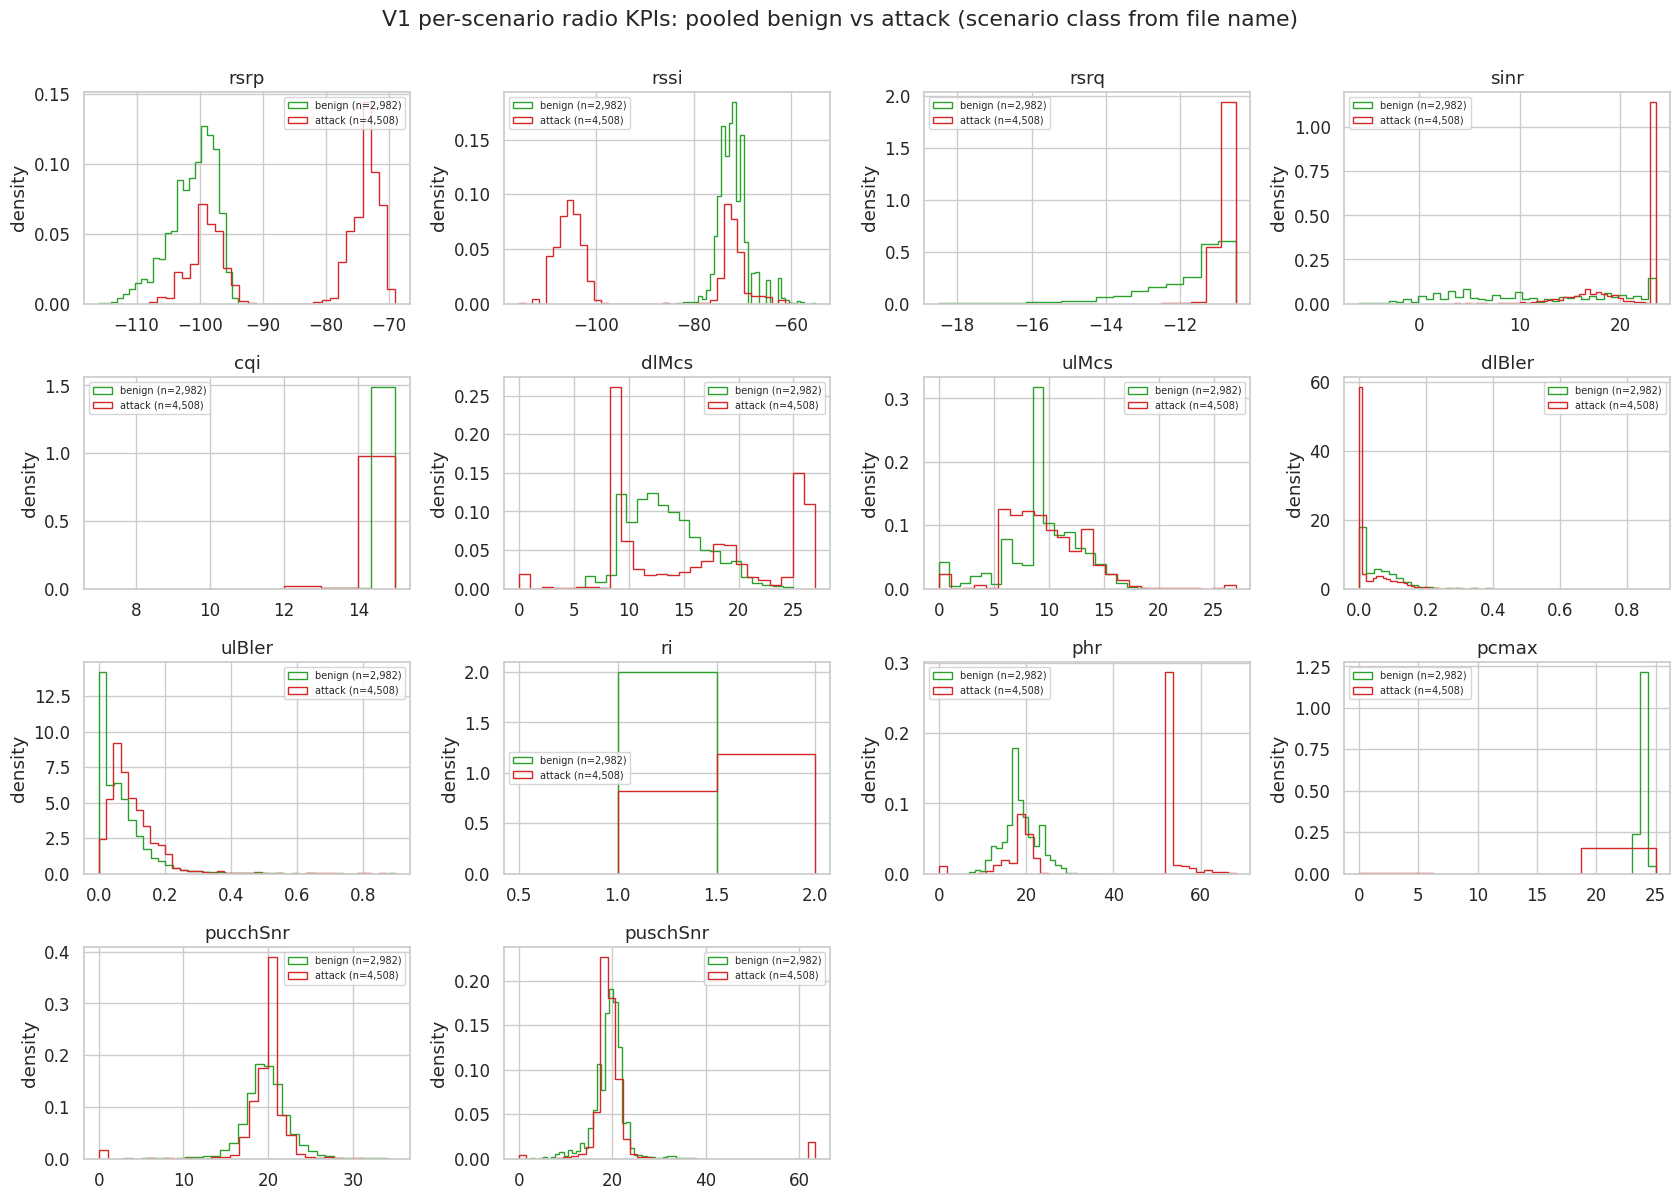

In [45]:
def kpi_hist_grid(df, grp_col, title, fname):
    fig, axes = plt.subplots(4, 4, figsize=(17, 12)); axes = axes.ravel()
    for ax, c in zip(axes, KPIS):
        for g, col in [("benign", "tab:green"), ("attack", "tab:red")]:
            v = pd.to_numeric(df.loc[df[grp_col] == g, c], errors="coerce").dropna()
            if len(v): ax.hist(v, bins=min(40, max(v.nunique(), 2)), density=True, histtype="step", lw=1.6, color=col, label=f"{g} (n={len(v):,})")
        ax.set_title(c); ax.set_ylabel("density"); ax.legend(fontsize=7)
    for ax in axes[len(KPIS):]: ax.axis("off")
    fig.suptitle(title, y=1.0); savefig(fname)
kpi_hist_grid(v1, "scenario_class_from_filename", "V1 per-scenario radio KPIs: pooled benign vs attack (scenario class from file name)", "kpi_distributions_v1")

*What this shows / does not show.* Overlaid, normalised histograms of each KPI for samples from benign-named and attack-named scenarios. Visible separation means the **pooled** distributions differ; because every benign sample comes from only six recordings made on one day, this can reflect recording conditions (radio position, UE count, time) instead of attack effects. It cannot, by itself, support a claim that the attack changes the radio KPI.

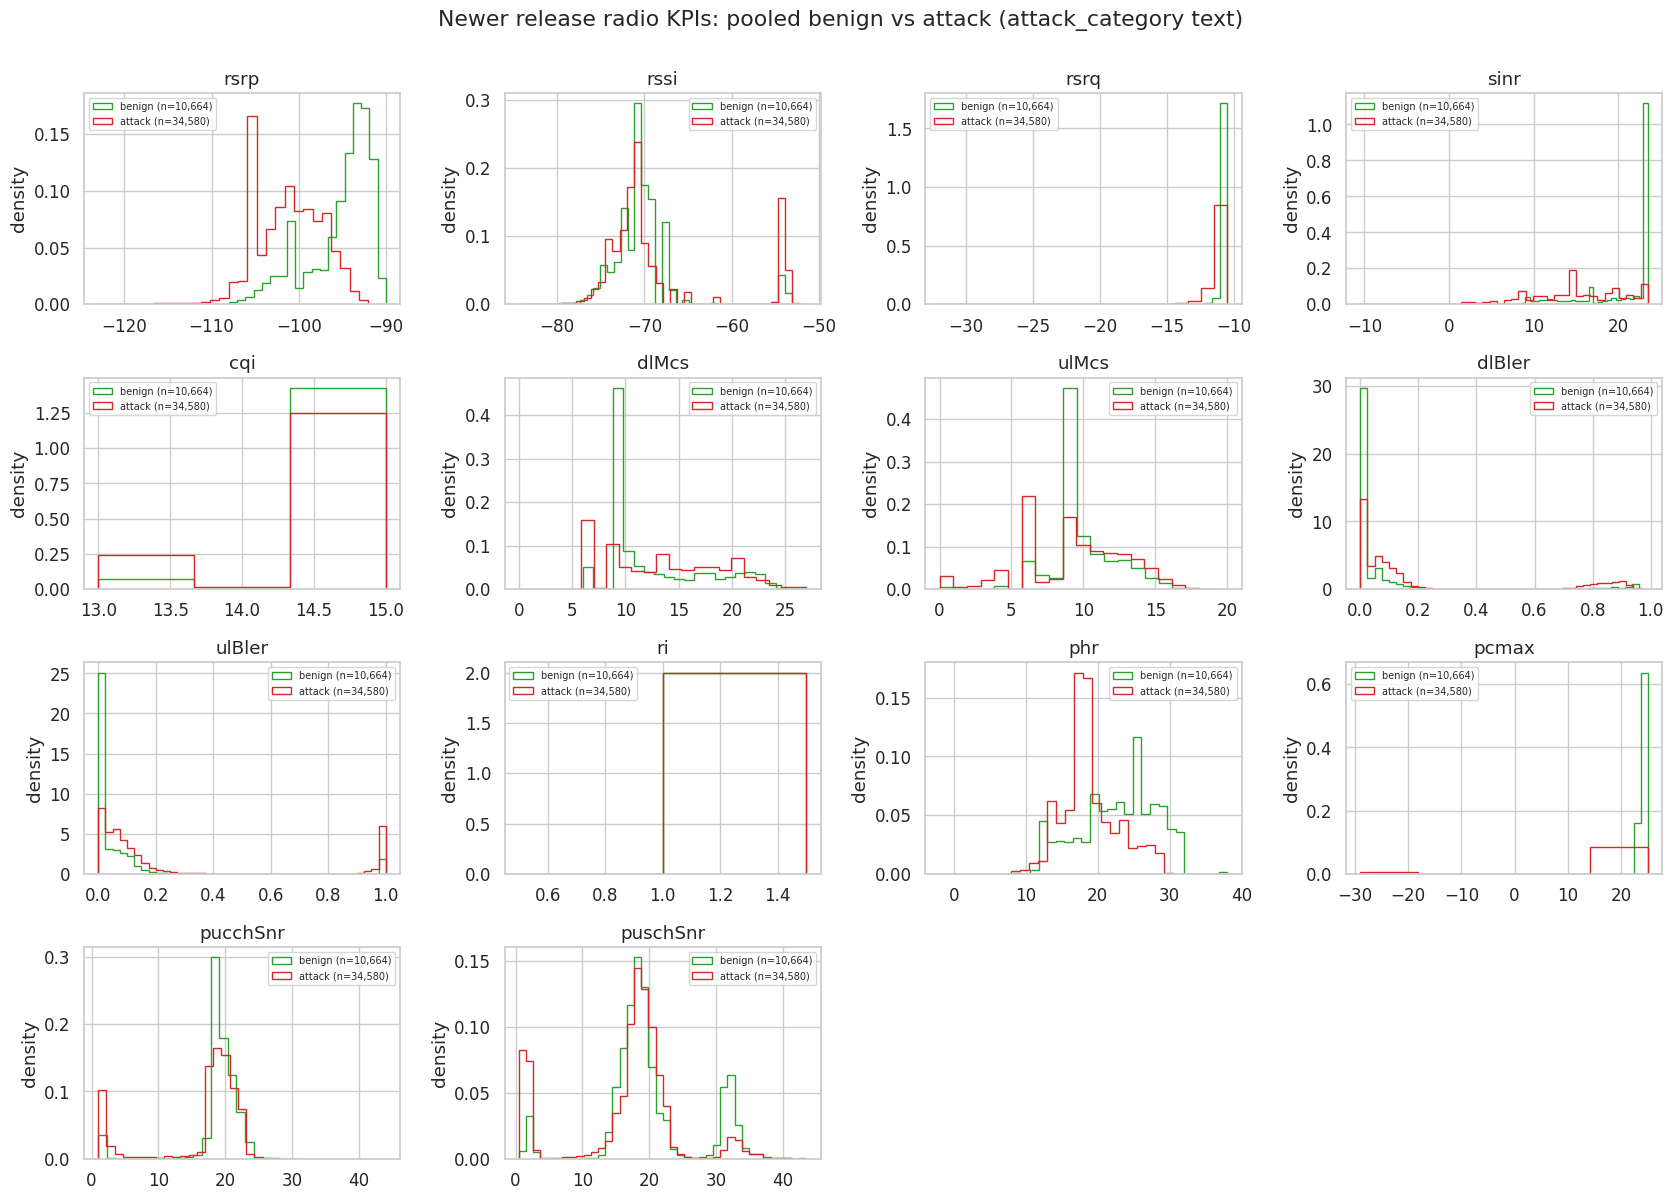

In [46]:
kpi_hist_grid(nwt, "binary_group", "Newer release radio KPIs: pooled benign vs attack (attack_category text)", "kpi_distributions_new")

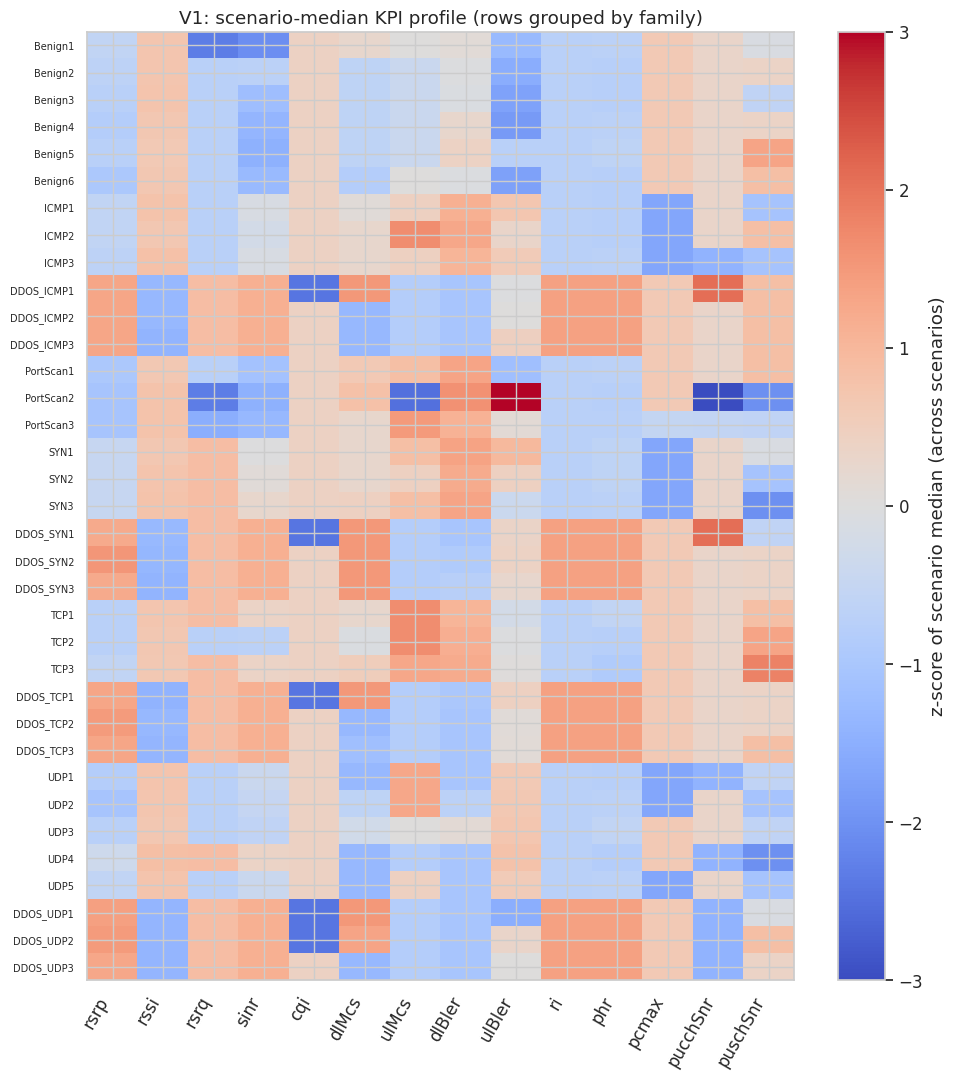

,rsrp,rssi,rsrq,sinr,cqi,dlMcs,ulMcs,dlBler,ulBler,ri,phr,pcmax,pucchSnr,puschSnr,family,start_utc
scenario,,,,,,,,,,,,,,,,
Benign1,-98.0,-72.00,-11.50,7.00,15.0,18.0,10.0,0.04,0.06,1.0,19.0,24.0,20.0,19.0,Benign,2025-04-14 12:34:37.522000+00:00
Benign2,-99.0,-72.00,-11.00,14.00,15.0,13.0,9.0,0.04,0.05,1.0,18.0,24.0,20.0,19.5,Benign,2025-04-14 12:40:13.522000+00:00
Benign3,-100.0,-71.50,-11.00,11.50,15.0,13.0,9.0,0.04,0.05,1.0,18.0,24.0,20.0,18.5,Benign,2025-04-14 12:50:27.522000+00:00
Benign4,-101.0,-72.70,-11.00,10.50,15.0,13.0,9.0,0.05,0.04,1.0,19.0,24.0,20.0,19.5,Benign,2025-04-14 12:59:10.522000+00:00
Benign5,-100.0,-73.40,-11.00,10.00,15.0,13.0,9.0,0.06,0.07,1.0,20.0,24.0,20.0,20.5,Benign,2025-04-14 13:08:32.522000+00:00
Benign6,-103.0,-72.70,-11.00,11.00,15.0,12.0,10.0,0.04,0.05,1.0,18.0,24.0,20.0,20.0,Benign,2025-04-14 13:13:58.522000+00:00
ICMP1,-98.0,-71.00,-11.00,17.00,15.0,17.0,11.0,0.09,0.09,1.0,18.0,23.0,20.0,18.0,ICMP,2025-03-06 15:30:47.614000+00:00
ICMP2,-98.0,-72.70,-11.00,16.50,15.0,18.0,14.0,0.09,0.09,1.0,18.0,23.0,20.0,20.0,ICMP,2025-03-06 15:33:54.634000+00:00
ICMP3,-99.0,-70.40,-11.00,17.00,15.0,18.0,11.0,0.08,0.09,1.0,19.0,23.0,19.0,18.0,ICMP,2025-03-06 15:36:50.634000+00:00


In [47]:
# scenario-level view: per-scenario medians (z-scored per KPI) -------------------------------------------------
med = v1.groupby("scenario")[KPIS].median().join(scn[["family", "start_utc"]]).sort_values(["family", "start_utc"])
z = (med[KPIS] - med[KPIS].mean()) / med[KPIS].std().replace(0, np.nan)
fig, ax = plt.subplots(figsize=(10, 11)); im = ax.imshow(z.values, aspect="auto", cmap="coolwarm", vmin=-3, vmax=3)
ax.set_xticks(range(len(KPIS))); ax.set_xticklabels(KPIS, rotation=60, ha="right"); ax.set_yticks(range(len(z))); ax.set_yticklabels(z.index, fontsize=7)
plt.colorbar(im, label="z-score of scenario median (across scenarios)"); ax.set_title("V1: scenario-median KPI profile (rows grouped by family)")
savefig("scenario_median_heatmap_v1")
display(med.round(2))

In [48]:
# effect sizes: pooled samples vs scenario-level medians -----------------------------------------------------------------
def prob_superiority(a, b):
    a, b = pd.Series(a).dropna(), pd.Series(b).dropna()
    if min(len(a), len(b)) < 5: return np.nan
    return stats.mannwhitneyu(a, b).statistic / (len(a) * len(b))
cls = scn.class_from_filename
rows = []
for c in KPIS:
    pooled = prob_superiority(v1.loc[v1.scenario_class_from_filename == "attack", c], v1.loc[v1.scenario_class_from_filename == "benign", c])
    scen = prob_superiority(med.loc[cls[med.index] == "attack", c], med.loc[cls[med.index] == "benign", c])
    rows.append({"kpi": c, "P(attack>benign) pooled samples": pooled, "P(attack>benign) scenario medians": scen,
                 "n_benign_scenarios": int((cls[med.index] == "benign").sum()), "n_attack_scenarios": int((cls[med.index] == "attack").sum())})
eff = pd.DataFrame(rows).set_index("kpi"); display(eff.round(3))
print("0.5 = no difference. The two columns answer different questions: pooled samples are strongly autocorrelated within a scenario, so the "
      "scenario-level column (n = number of recordings) is the honest effective sample size.")

,P(attack>benign) pooled samples,P(attack>benign) scenario medians,n_benign_scenarios,n_attack_scenarios
kpi,,,,
rsrp,0.862,0.767,6,29
rssi,0.225,0.417,6,29
rsrq,0.795,0.810,6,29
sinr,0.845,0.948,6,29
cqi,0.357,0.414,6,29
dlMcs,0.598,0.672,6,29
ulMcs,0.477,0.511,6,29
dlBler,0.313,0.437,6,29
ulBler,0.668,0.983,6,29


0.5 = no difference. The two columns answer different questions: pooled samples are strongly autocorrelated within a scenario, so the scenario-level column (n = number of recordings) is the honest effective sample size.


### 7.x Relationships between KPIs

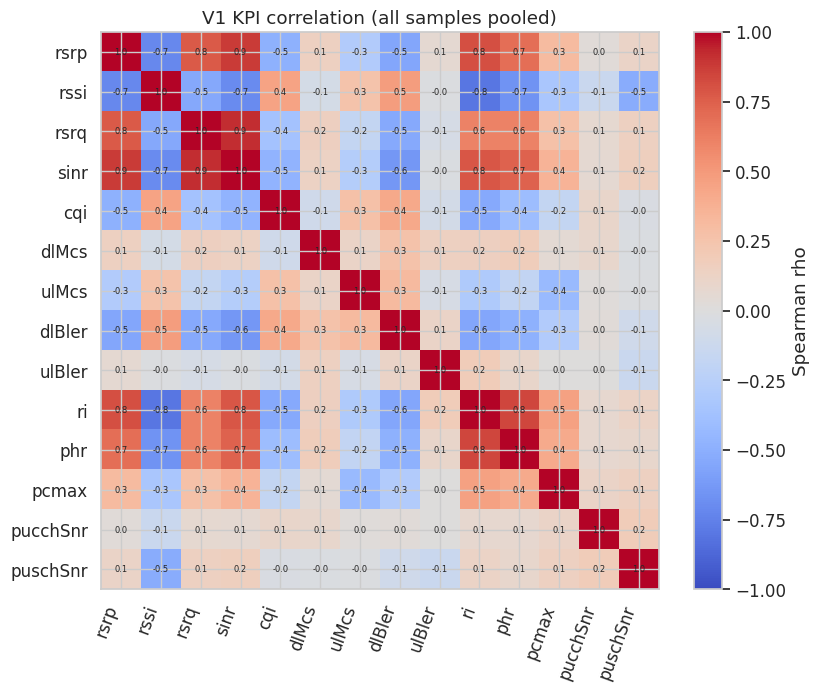

KPI pairs with |rho| > 0.9 (reported only, nothing removed): [('rsrq', 'sinr', np.float64(0.91))]


In [49]:
corr = v1[KPIS].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8.5, 7)); im = ax.imshow(corr.values, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(KPIS))); ax.set_xticklabels(KPIS, rotation=70, ha="right"); ax.set_yticks(range(len(KPIS))); ax.set_yticklabels(KPIS)
for i in range(len(KPIS)):
    for j in range(len(KPIS)): ax.text(j, i, f"{corr.values[i, j]:.1f}", ha="center", va="center", fontsize=6)
plt.colorbar(im, label="Spearman rho"); ax.set_title("V1 KPI correlation (all samples pooled)"); savefig("kpi_correlation_v1")
pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(KPIS) for b in KPIS[i + 1:] if abs(corr.loc[a, b]) > .9]
print("KPI pairs with |rho| > 0.9 (reported only, nothing removed):", [(a, b, round(r, 2)) for a, b, r in pairs] or "none")

In [50]:
# per-scenario statistics file (V1 scenarios + newer-release recordings) -------------------------------------------------------
def scen_stats(df, key, name, extra):
    g = df.groupby(key)
    t = g.agg(rows=("ue_id", "size"), n_ue=("ue_id", "nunique"), start_utc=("time_utc", "min"), end_utc=("time_utc", "max"), **extra)
    t["duration_s"] = (t.end_utc - t.start_utc).dt.total_seconds()
    for c in KPIS + COUNTERS:
        t[f"{c}_mean"] = g[c].mean(); t[f"{c}_std"] = g[c].std()
    t.insert(0, "dataset", name); t.index.name = "scenario_or_recording"; return t.reset_index()
ss = pd.concat([scen_stats(v1, "scenario", "V1", {"family": ("family", "first"), "class_from_filename": ("scenario_class_from_filename", "first")}),
                scen_stats(nwt, "recording_id", "newer", {"attack_category": ("attack_category", "first"), "attack_subcategory": ("attack_subcategory", "first"),
                                                          "recording_id_basis": ("recording_id_basis", "first")})], ignore_index=True)
save_csv(ss, "scenario_statistics.csv")

saved: /kaggle/working/analysis/radio_outputs/scenario_statistics.csv (81, 44)


---
## 8 · UE, Cell, and RNTI Investigation
Identifiers are **kept** (they may be needed for alignment). The question here is whether they reveal the scenario, which would make them unsuitable as *model features* later.

In [51]:
print("cellid vs family (V1):"); display(pd.crosstab(v1.family, v1.cellid, margins=True))
print("cellid vs DDOS flag among attack scenarios:"); display(pd.crosstab(v1.loc[v1.scenario_class_from_filename == "attack", "ddos"], v1.loc[v1.scenario_class_from_filename == "attack", "cellid"]))
ue_s = v1.groupby("scenario").ue_id.agg(["nunique", lambda s: sorted(s.unique().astype(int).tolist())]); ue_s.columns = ["n_ue", "ue_ids"]; display(ue_s)
print("UE ids by scenario class:"); display(pd.crosstab(v1.ue_id, v1.scenario_class_from_filename))

cellid vs family (V1):


cellid,11111111,12345678,All
family,,,
Benign,2982,0,2982
ICMP,357,703,1060
PortScan,26,0,26
SYN,375,665,1040
TCP,373,675,1048
UDP,622,712,1334
All,4735,2755,7490


cellid vs DDOS flag among attack scenarios:


cellid,11111111,12345678
ddos,,
0,1753,0
1,0,2755


,n_ue,ue_ids
scenario,,
Benign1,2,"[1, 2]"
Benign2,3,"[2, 5, 8]"
Benign3,2,"[2, 8]"
Benign4,2,"[2, 8]"
Benign5,2,"[2, 8]"
Benign6,2,"[2, 8]"
DDOS_ICMP1,3,"[148, 149, 150]"
DDOS_ICMP2,2,"[149, 150]"
DDOS_ICMP3,2,"[149, 150]"


UE ids by scenario class:


scenario_class_from_filename,attack,benign
ue_id,,
1,277,129
2,0,1519
3,1216,0
4,260,0
5,0,156
8,0,1178
104,225,0
111,81,0
112,57,0


In [52]:
r_per_ue = v1.groupby(["scenario", "ue_id"]).rnti.nunique().rename("distinct_rnti_per_ue_in_scenario").reset_index()
print("RNTI values per (scenario, UE): median =", r_per_ue.distinct_rnti_per_ue_in_scenario.median(), "| max =", r_per_ue.distinct_rnti_per_ue_in_scenario.max())
scn_per_rnti = v1.groupby("rnti").scenario.nunique()
print(f"distinct rnti values: {v1.rnti.nunique()} | seen in exactly one scenario: {(scn_per_rnti == 1).sum()} ({100*(scn_per_rnti == 1).mean():.1f}% of values) | in >1 scenario: {(scn_per_rnti > 1).sum()}")
print("share of ROWS whose rnti value belongs to a single scenario:", f"{v1.rnti.map(scn_per_rnti).eq(1).mean():.1%}")
print("\nCramér's V (association of identifier with scenario / with class-from-filename):")
for c in ["ue_id", "rnti", "cellid", "in_sync"]:
    print(f"  {c:8s} vs scenario: {cramers_v(v1[c].astype(str), v1.scenario):.3f} | vs class: {cramers_v(v1[c].astype(str), v1.scenario_class_from_filename):.3f}")
print("\nnewer release (recordings):")
print("ue_id vs binary_group:"); display(pd.crosstab(nwt.ue_id, nwt.binary_group))
print("cellid values:", nwt.cellid.dropna().unique().tolist()[:10])
print("rnti values seen in exactly one recording: ", f"{(nwt.groupby('rnti').recording_id.nunique() == 1).mean():.1%}" if "rnti" in nwt.columns else "n/a")

RNTI values per (scenario, UE): median = 1.0 | max = 5
distinct rnti values: 44 | seen in exactly one scenario: 28 (63.6% of values) | in >1 scenario: 16
share of ROWS whose rnti value belongs to a single scenario: 11.3%

Cramér's V (association of identifier with scenario / with class-from-filename):
  ue_id    vs scenario: 0.677 | vs class: 0.975
  rnti     vs scenario: 0.592 | vs class: 1.000
  cellid   vs scenario: 1.000 | vs class: 0.620
  in_sync  vs scenario: nan | vs class: nan

newer release (recordings):
ue_id vs binary_group:


binary_group,attack,benign
ue_id,,
1.0,23241,4265
2.0,492,4028
3.0,0,51
4.0,4914,917
5.0,3770,0
6.0,1144,0
13.0,592,0
15.0,427,954
18.0,0,449


cellid values: [11111111.0]
rnti values seen in exactly one recording:  51.1%


In [53]:
display(v1[["pmi", "pmi_0", "pmi_1", "ri"]].astype(str).apply(lambda s: s.value_counts().head(6)).T if "pmi" in v1.columns else "no pmi column")
print("pmi distinct values:", v1["pmi"].nunique() if "pmi" in v1.columns else "n/a", "| stored as text tuple '(a, b)' in the source files (split into pmi_0/pmi_1 only in the in-memory copy)")

,"(0,0)","(13,1)","(15,0)","(4,1)","(8,1)","(9,1)",0,1,13,15,2,4,8,9
pmi,4822.0,562.0,278.0,233.0,214.0,348.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pmi_0,NaN,NaN,NaN,NaN,NaN,NaN,4822.0,NaN,706.0,439.0,NaN,282.0,255.0,418.0
pmi_1,NaN,NaN,NaN,NaN,NaN,NaN,5586.0,1904.0,NaN,NaN,NaN,NaN,NaN,NaN
ri,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4822.0,NaN,NaN,2668.0,NaN,NaN,NaN


pmi distinct values: 19 | stored as text tuple '(a, b)' in the source files (split into pmi_0/pmi_1 only in the in-memory copy)


---
## 9 · Byte Counter Investigation
`dlBytes` / `ulBytes` are tested for **cumulative-counter semantics**, but only **inside one (scenario, UE) series sorted by timestamp**. V1 files are not stored in a consistent order (some newest-first), so the previous interpretation of "decreasing values" as an anomaly needs to be checked against the file order. Original columns are never replaced.

In [54]:
def counter_report(df, keys, ts="timestamp_ms"):
    rows = []
    for k, g in df.sort_values(keys + [ts]).groupby(keys, sort=False):
        for c in COUNTERS:
            d = g[c].diff().dropna()
            rows.append({"key": k if not isinstance(k, tuple) else "|".join(map(str, k)), "counter": c, "n_pairs": len(d), "neg_deltas": int((d < 0).sum()),
                         "monotonic": bool((d >= 0).all()), "median_delta": d.median(), "p99_delta": d.quantile(.99), "max_delta": d.max(),
                         "max_over_median": (d.max() / d.median()) if d.median() > 0 else np.nan})
    return pd.DataFrame(rows)
cr = counter_report(v1, ["scenario", "ue_id"])
summ = cr.groupby("counter").agg(series=("key", "size"), monotonic_series=("monotonic", "sum"), neg_deltas=("neg_deltas", "sum"), pairs=("n_pairs", "sum"))
summ["monotonic_share"] = (summ.monotonic_series / summ.series).round(3); display(summ)
display(cr[~cr.monotonic].sort_values("neg_deltas", ascending=False).head(15))
FINDINGS["bytes_monotonic_share"] = summ.monotonic_share.to_dict()

# effect of FILE ORDER: same data diffed in stored order --------------------------------------------------------------
fo = v1.sort_values(["scenario", "ue_id", "file_row"]); stored_neg = fo.groupby(["scenario", "ue_id"])["dlBytes"].diff().lt(0)
print(f"\nnegative dlBytes deltas when diffed in STORED file order : {stored_neg.sum():,} ({100*stored_neg.mean():.1f}% of rows)")
print(f"negative dlBytes deltas when diffed in TIMESTAMP order   : {int(summ.loc['dlBytes', 'neg_deltas']):,}")
print("files stored newest-first:", sorted(v1.loc[v1.file_order_desc, "scenario"].unique().tolist()))
print("file order direction vs class:"); display(pd.crosstab(scn.class_from_filename, scn.file_order_desc, rownames=["class"], colnames=["stored newest-first"]))

,series,monotonic_series,neg_deltas,pairs,monotonic_share
counter,,,,,
dlBytes,60,51,21,7430,0.85
ulBytes,60,51,21,7430,0.85


,key,counter,n_pairs,neg_deltas,monotonic,median_delta,p99_delta,max_delta,max_over_median
73,DDOS_UDP1|112,ulBytes,56,4,False,0.0,15771.05,16601.0,NaN
72,DDOS_UDP1|112,dlBytes,56,4,False,6005.0,86627.65,87297.0,14.537386
70,DDOS_UDP1|111,dlBytes,80,4,False,12294.5,85952.00,85952.0,6.991094
71,DDOS_UDP1|111,ulBytes,80,4,False,4847.0,26722.32,27743.0,5.723747
27,DDOS_ICMP1|148,ulBytes,76,3,False,6484.0,16900.75,21868.0,3.372610
26,DDOS_ICMP1|148,dlBytes,76,3,False,18906.0,85952.00,85952.0,4.546282
31,DDOS_ICMP1|150,ulBytes,58,3,False,10130.0,20647.72,20707.0,2.044126
30,DDOS_ICMP1|150,dlBytes,58,3,False,70103.5,83895.39,84735.0,1.208713
55,DDOS_TCP1|143,ulBytes,86,3,False,10333.0,29655.85,37475.0,3.626730
54,DDOS_TCP1|143,dlBytes,86,3,False,175098.5,214678.50,217169.0,1.240268



negative dlBytes deltas when diffed in STORED file order : 7,292 (97.4% of rows)
negative dlBytes deltas when diffed in TIMESTAMP order   : 21
files stored newest-first: ['Benign1', 'Benign2', 'Benign3', 'Benign4', 'Benign5', 'Benign6', 'DDOS_UDP1', 'DDOS_UDP2', 'DDOS_UDP3', 'ICMP1', 'ICMP2', 'ICMP3', 'PortScan1', 'PortScan2', 'PortScan3', 'SYN1', 'SYN2', 'SYN3', 'TCP1', 'TCP2', 'TCP3', 'UDP1', 'UDP2', 'UDP3', 'UDP4', 'UDP5']
file order direction vs class:


stored newest-first,False,True
class,,
attack,9,20
benign,0,6


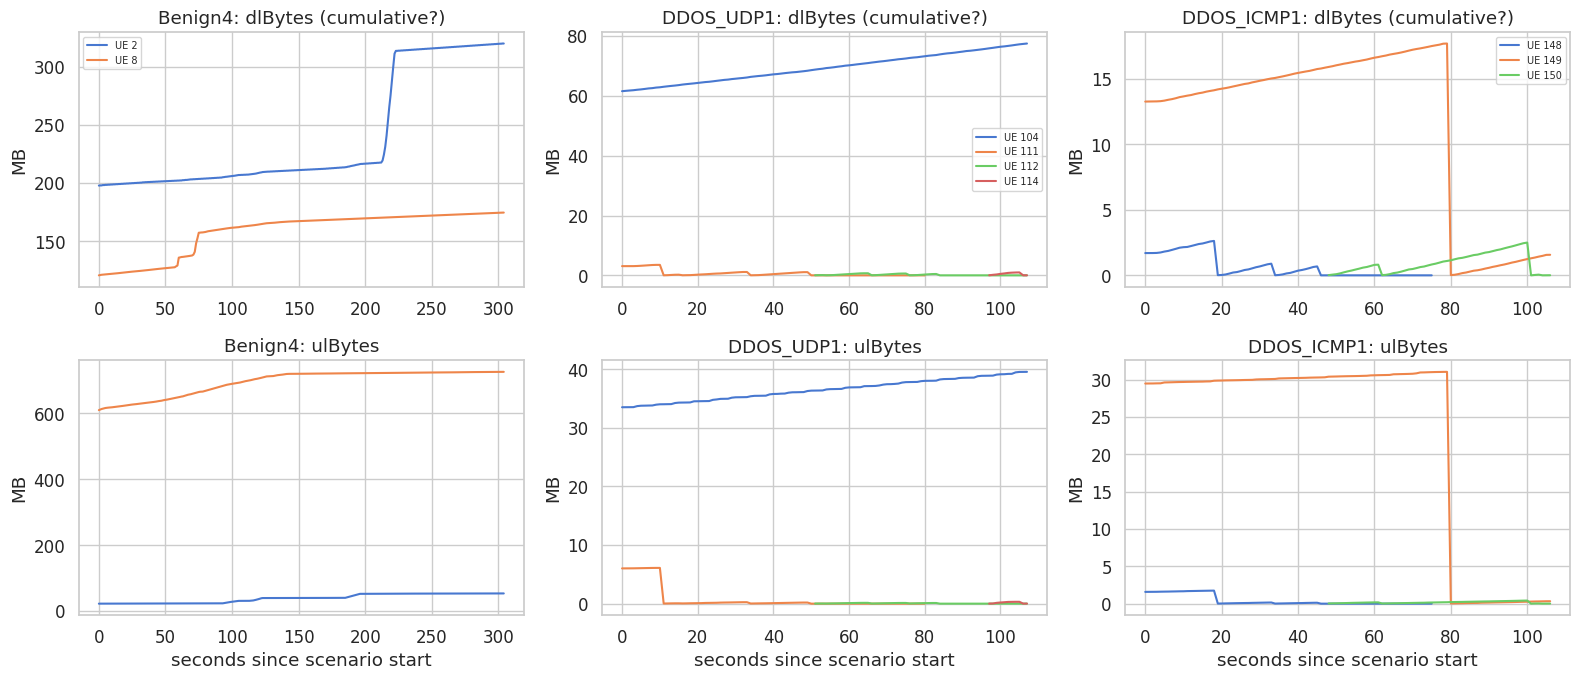

In [55]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
picks = [("benign", None), ("attack", None)]
sel = []
ben = scn[scn.class_from_filename == "benign"].sort_values("rows", ascending=False).index[:1].tolist()
att = scn[scn.class_from_filename == "attack"].sort_values("rows", ascending=False).index[:2].tolist()
for ax_col, s in zip(range(3), ben + att):
    g = v1t[v1t.scenario == s]
    for ue, gg in g.groupby("ue_id"):
        axes[0, ax_col].plot((gg.timestamp_ms - g.timestamp_ms.min()) / 1000, gg.dlBytes / 1e6, label=f"UE {int(ue)}"); axes[1, ax_col].plot((gg.timestamp_ms - g.timestamp_ms.min()) / 1000, gg.ulBytes / 1e6, label=f"UE {int(ue)}")
    axes[0, ax_col].set_title(f"{s}: dlBytes (cumulative?)"); axes[1, ax_col].set_title(f"{s}: ulBytes"); axes[1, ax_col].set_xlabel("seconds since scenario start")
    axes[0, ax_col].set_ylabel("MB"); axes[1, ax_col].set_ylabel("MB"); axes[0, ax_col].legend(fontsize=7)
savefig("byte_counters_timeseries_v1")

In [56]:
d = pd.concat([cr[cr.counter == "dlBytes"].n_pairs.rename("pairs"), cr[cr.counter == "dlBytes"].median_delta.rename("median_delta")], axis=1)
print("Interpretation (computed): monotonic share dlBytes =", f"{summ.loc['dlBytes', 'monotonic_share']:.1%}", "| ulBytes =", f"{summ.loc['ulBytes', 'monotonic_share']:.1%}")
print("Median per-second increment of dlBytes across series:", f"{d.median_delta.median():,.0f} bytes (a cumulative counter's increment is the per-interval traffic)")
print("Recommendation for a LATER stage (not applied here): raw counters encode position inside a recording; per-interval deltas computed per (recording, UE) in timestamp order are the physically meaningful quantity; resets/negative deltas listed above must be treated explicitly.")

Interpretation (computed): monotonic share dlBytes = 85.0% | ulBytes = 85.0%
Median per-second increment of dlBytes across series: 55,600 bytes (a cumulative counter's increment is the per-interval traffic)
Recommendation for a LATER stage (not applied here): raw counters encode position inside a recording; per-interval deltas computed per (recording, UE) in timestamp order are the physically meaningful quantity; resets/negative deltas listed above must be treated explicitly.


---
## 10 · Temporal Analysis
Timestamp format, time range per scenario, sampling frequency per UE, gaps, repeated timestamps and KPI behaviour over time. Timestamps are epoch **milliseconds**, which are UTC by definition; any timezone shift observed elsewhere (e.g. in network packet files) is a property of the *other* modality and is handled by the alignment audit, not here.

In [57]:
g = v1t.copy(); g["step_ms"] = g.groupby(["scenario", "ue_id"]).timestamp_ms.diff()
ue_per_ts = v1.groupby(["scenario", "timestamp_ms"]).ue_id.nunique()
tt = scn[["class_from_filename", "family", "rows", "n_ue", "start_utc", "end_utc", "duration_s", "file_order_desc"]].copy()
tt["median_step_ms"] = g.groupby("scenario").step_ms.median(); tt["share_step_1000ms"] = g.assign(x=g.step_ms == 1000).groupby("scenario").x.mean().round(3)
tt["max_gap_s"] = g.groupby("scenario").step_ms.max() / 1000; tt["gaps_gt_5s"] = g.assign(x=g.step_ms > 5000).groupby("scenario").x.sum()
tt["ue_rows_per_timestamp"] = ue_per_ts.groupby("scenario").mean().round(2)
tt["expected_rows_if_1Hz"] = (tt.duration_s + 1) * tt.n_ue; tt["row_coverage_vs_1Hz"] = (tt.rows / tt.expected_rows_if_1Hz).round(3)
display(tt.sort_values("start_utc"))
print("overall median step (ms):", g.step_ms.median(), "| share of steps exactly 1000 ms:", f"{(g.step_ms == 1000).mean():.1%}", "| steps > 5 s:", int((g.step_ms > 5000).sum()))
print("period:", v1.time_utc.min(), "->", v1.time_utc.max())
print("scenario time ranges overlap each other?", bool((scn.sort_values('start_utc').start_utc.iloc[1:].values < scn.sort_values('start_utc').end_utc.iloc[:-1].values).any()))
FINDINGS.update(v1_median_step=g.step_ms.median(), v1_step1000=float((g.step_ms == 1000).mean()))

,class_from_filename,family,rows,n_ue,start_utc,end_utc,duration_s,file_order_desc,median_step_ms,share_step_1000ms,max_gap_s,gaps_gt_5s,ue_rows_per_timestamp,expected_rows_if_1Hz,row_coverage_vs_1Hz
scenario,,,,,,,,,,,,,,,
PortScan1,attack,PortScan,9,1,2025-02-27 13:39:07.404000+00:00,2025-02-27 13:39:14.404000+00:00,7.000,True,1000.0,0.778,1.000,0,1.00,8.000,1.125
PortScan2,attack,PortScan,9,1,2025-02-27 13:42:24.404000+00:00,2025-02-27 13:42:31.404000+00:00,7.000,True,1000.0,0.778,1.000,0,1.00,8.000,1.125
PortScan3,attack,PortScan,8,1,2025-02-27 13:43:50.404000+00:00,2025-02-27 13:43:56.404000+00:00,6.000,True,1000.0,0.750,1.000,0,1.00,7.000,1.143
UDP1,attack,UDP,126,1,2025-02-27 13:45:50.404000+00:00,2025-02-27 13:47:54.404000+00:00,124.000,True,1000.0,0.984,1.000,0,1.00,125.000,1.008
UDP2,attack,UDP,125,1,2025-02-27 13:49:37.404000+00:00,2025-02-27 13:51:40.404000+00:00,123.000,True,1000.0,0.984,1.000,0,1.00,124.000,1.008
UDP3,attack,UDP,125,1,2025-03-06 14:09:49.464000+00:00,2025-03-06 14:11:52.464000+00:00,123.000,True,1000.0,0.984,1.000,0,1.00,124.000,1.008
UDP4,attack,UDP,119,1,2025-03-06 14:13:11.464000+00:00,2025-03-06 14:15:08.464000+00:00,117.000,True,1000.0,0.983,1.000,0,1.00,118.000,1.008
UDP5,attack,UDP,127,1,2025-03-06 14:20:29.464000+00:00,2025-03-06 14:22:34.464000+00:00,125.000,True,1000.0,0.984,1.000,0,1.00,126.000,1.008
TCP1,attack,TCP,125,1,2025-03-06 14:37:54.464000+00:00,2025-03-06 14:39:57.464000+00:00,123.000,True,1000.0,0.984,1.000,0,1.00,124.000,1.008


overall median step (ms): 1000.0 | share of steps exactly 1000 ms: 91.4% | steps > 5 s: 0
period: 2025-02-27 13:39:07.404000+00:00 -> 2025-04-14 13:19:01.522000+00:00
scenario time ranges overlap each other? False


In [58]:
# repeated timestamps: legitimate multi-UE sampling or artefact? ----------------------------------------------------------
cnt = v1.groupby(["scenario", "timestamp_ms"]).agg(rows=("ue_id", "size"), ues=("ue_id", "nunique"))
shared = cnt[cnt.rows > 1]
print(f"timestamps shared by >1 row: {len(shared):,} of {len(cnt):,} ({100*len(shared)/len(cnt):.1f}%)")
print("of those, rows == distinct UEs (i.e. explained by several UEs sampled at the same instant):", f"{(shared.rows == shared.ues).mean():.1%}")
print("timestamps with MORE rows than distinct UEs (same UE twice at the same ms):", int((cnt.rows > cnt.ues).sum()))
print("\nrow count per unique timestamp:"); display(cnt.rows.value_counts().sort_index().to_frame("n_timestamps"))

timestamps shared by >1 row: 2,413 of 5,012 (48.1%)
of those, rows == distinct UEs (i.e. explained by several UEs sampled at the same instant): 98.5%
timestamps with MORE rows than distinct UEs (same UE twice at the same ms): 35

row count per unique timestamp:


,n_timestamps
rows,
1,2599
2,2348
3,65


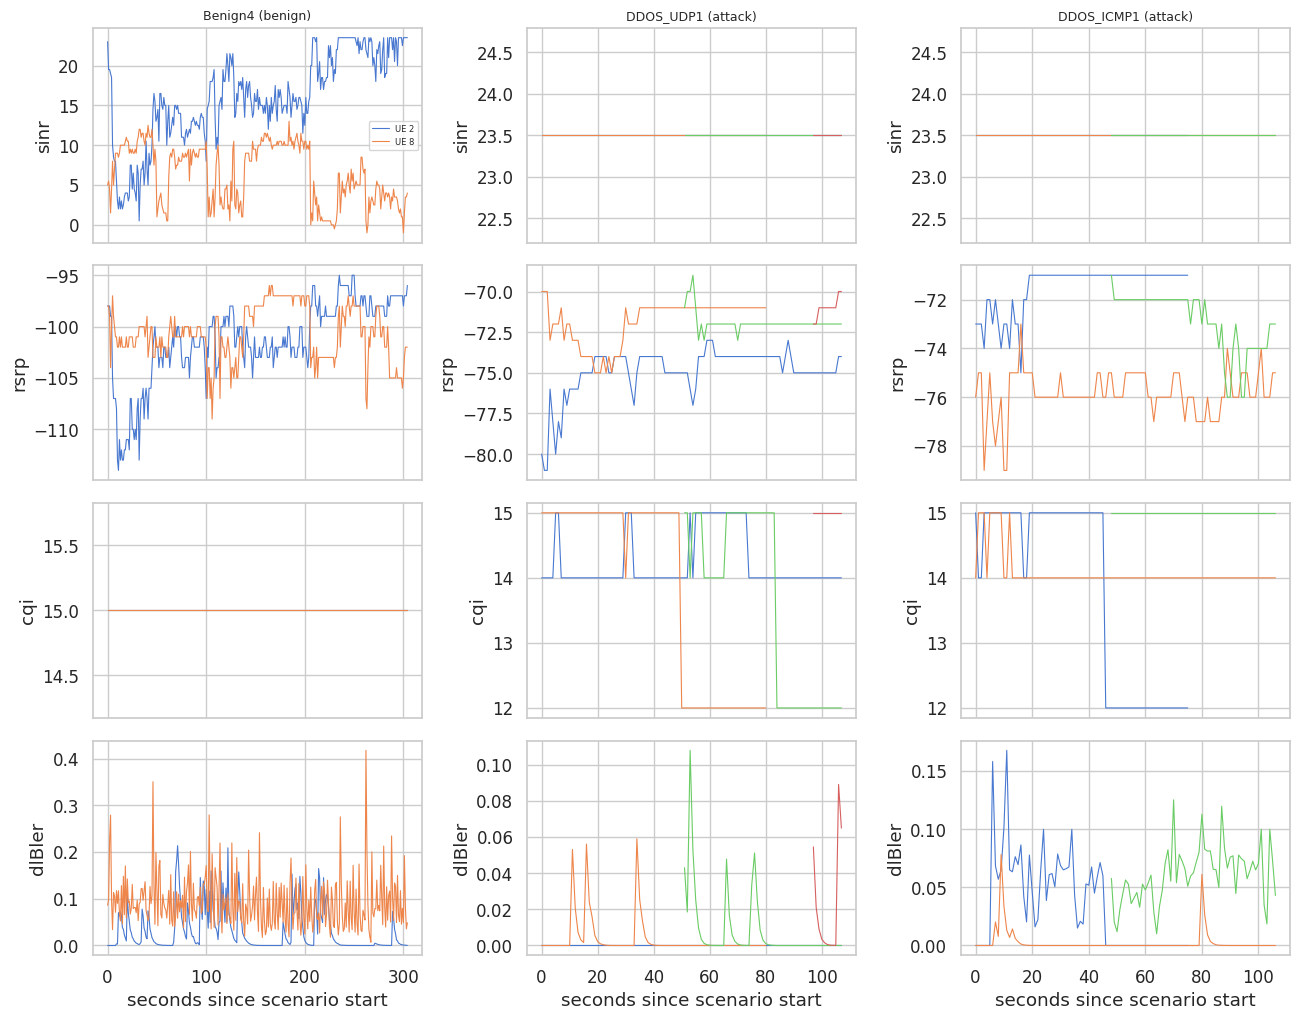

In [59]:
# KPI behaviour over time ---------------------------------------------------------------------------------------------------
show = ben + att + scn[(scn.class_from_filename == "attack") & (scn.ddos == 1)].sort_values("rows", ascending=False).index[:1].tolist()
show = list(dict.fromkeys(show))[:4]; kp = ["sinr", "rsrp", "cqi", "dlBler"]
fig, axes = plt.subplots(len(kp), len(show), figsize=(4.4 * len(show), 2.6 * len(kp)), sharex="col", squeeze=False)
for j, s in enumerate(show):
    gs = v1t[v1t.scenario == s]; t0 = gs.timestamp_ms.min()
    for i, k in enumerate(kp):
        for ue, gg in gs.groupby("ue_id"): axes[i, j].plot((gg.timestamp_ms - t0) / 1000, gg[k], lw=.8, label=f"UE {int(ue)}")
        axes[i, j].set_ylabel(k)
        if i == 0: axes[i, j].set_title(f"{s} ({scn.class_from_filename[s]})", fontsize=9)
    axes[-1, j].set_xlabel("seconds since scenario start")
axes[0, 0].legend(fontsize=6); savefig("kpi_timeseries_v1")

*What this shows / does not show.* KPI traces per UE for a benign scenario and several attack scenarios. Use it to see whether a KPI changes *within* a recording (e.g. at attack onset) or is simply at a different level in different recordings. Because the V1 attack scenarios are separate files without a marked onset time, the plots cannot establish *when* the attack starts inside a recording.

In [60]:
# sudden changes (robust jump rate) -------------------------------------------------------------------------------------------------
rows = []
for (s, ue), gg in v1t.groupby(["scenario", "ue_id"]):
    r = {"scenario": s, "ue_id": ue, "n": len(gg)}
    for k in ["sinr", "rsrp", "cqi", "dlBler", "dlMcs"]:
        d = gg[k].diff().dropna(); mad = 1.4826 * np.median(np.abs(d - d.median()))
        r[f"{k}_jumps_per_100"] = round(100 * (np.abs(d) > 6 * mad).mean(), 2) if mad > 0 else np.nan
    rows.append(r)
jumps = pd.DataFrame(rows); display(jumps.groupby("scenario").mean(numeric_only=True).round(2).join(scn.class_from_filename).sort_values("class_from_filename"))
print("jump = |x_t - x_(t-1)| > 6 x robust sigma of that UE's own differences (NaN when the series has zero robust spread).")

,ue_id,n,sinr_jumps_per_100,rsrp_jumps_per_100,cqi_jumps_per_100,dlBler_jumps_per_100,dlMcs_jumps_per_100,class_from_filename
scenario,,,,,,,,
DDOS_UDP3,132.00,112.0,NaN,NaN,NaN,NaN,NaN,attack
ICMP2,4.00,125.0,1.61,NaN,NaN,0.81,8.06,attack
ICMP3,4.00,129.0,4.69,NaN,NaN,0.00,0.00,attack
PortScan1,1.00,9.0,0.00,0.00,NaN,0.00,0.00,attack
PortScan2,1.00,9.0,0.00,0.00,NaN,0.00,0.00,attack
PortScan3,1.00,8.0,0.00,0.00,NaN,0.00,0.00,attack
SYN1,3.00,126.0,1.60,NaN,NaN,0.00,2.40,attack
ICMP1,3.50,51.5,1.04,NaN,NaN,0.00,0.00,attack
SYN2,3.00,125.0,0.81,NaN,NaN,0.00,0.00,attack


jump = |x_t - x_(t-1)| > 6 x robust sigma of that UE's own differences (NaN when the series has zero robust spread).


In [61]:
# newer release temporal table (per recording) -------------------------------------------------------------------------------------
gn = nwt.dropna(subset=["timestamp_ms"]).sort_values(["recording_id", "ue_id", "timestamp_ms"]).copy(); gn["step_ms"] = gn.groupby(["recording_id", "ue_id"]).timestamp_ms.diff()
rt = nwt.groupby("recording_id").agg(rows=("ue_id", "size"), n_ue=("ue_id", "nunique"), category=("attack_category", "first"), subcat=("attack_subcategory", "first"),
        start_utc=("time_utc", "min"), end_utc=("time_utc", "max"), basis=("recording_id_basis", "first"))
rt["duration_s"] = (rt.end_utc - rt.start_utc).dt.total_seconds(); rt["median_step_ms"] = gn.groupby("recording_id").step_ms.median()
rt["share_step_1000ms"] = gn.assign(x=gn.step_ms == 1000).groupby("recording_id").x.mean().round(3); rt["gaps_gt_5s"] = gn.assign(x=gn.step_ms > 5000).groupby("recording_id").x.sum()
display(rt.sort_values("start_utc"))
print("newer-release period:", nwt.time_utc.min(), "->", nwt.time_utc.max(), "| recordings:", len(rt), "| traced:", int((rt.basis.str.startswith('raw')).sum()), "| reconstructed:", int((~rt.basis.str.startswith('raw')).sum()))
print("rows with missing timestamp:", int(nwt.timestamp_ms.isna().sum()))

,rows,n_ue,category,subcat,start_utc,end_utc,basis,duration_s,median_step_ms,share_step_1000ms,gaps_gt_5s
recording_id,,,,,,,,,,,
benign_1,912,1,Benign,Benign,2025-05-09 14:05:06.701000+00:00,2025-05-09 14:20:17.701000+00:00,raw file name (traced),911.000,1000.0,0.999,0
benign_2,879,1,Benign,Benign,2025-05-09 14:48:56.075000+00:00,2025-05-09 15:03:34.075000+00:00,raw file name (traced),878.000,1000.0,0.999,0
benign_4,935,1,Benign,Benign,2025-05-12 10:04:16.486000+00:00,2025-05-12 10:19:50.486000+00:00,raw file name (traced),934.000,1000.0,0.997,0
benign_5,890,1,Benign,Benign,2025-05-12 12:01:14.329000+00:00,2025-05-12 12:16:03.329000+00:00,raw file name (traced),889.000,1000.0,0.999,0
benign_3,393,1,Benign,Benign,2025-05-12 13:34:08.108000+00:00,2025-05-12 13:40:40.128000+00:00,raw file name (traced),392.020,1000.0,0.995,0
benign_6,909,1,Benign,Benign,2025-05-13 11:37:24.551000+00:00,2025-05-13 11:52:32.551000+00:00,raw file name (traced),908.000,1000.0,0.999,0
benign_7,968,2,Benign,Benign,2025-05-13 13:01:57.808000+00:00,2025-05-13 13:19:19.174000+00:00,raw file name (traced),1041.366,1000.0,0.998,0
benign_8,1520,1,Benign,Benign,2025-05-13 13:59:39.917000+00:00,2025-05-13 14:30:26.177000+00:00,raw file name (traced),1846.260,1000.0,0.994,8
benign_9,901,1,Benign,Benign,2025-05-15 14:58:09.652000+00:00,2025-05-15 15:13:09.652000+00:00,raw file name (traced),900.000,1000.0,0.999,0


newer-release period: 2025-05-09 14:05:06.701000+00:00 -> 2025-07-01 13:09:17.835000+00:00 | recordings: 46 | traced: 40 | reconstructed: 6
rows with missing timestamp: 0


**Radio-side facts for the alignment audit (verified above, no alignment is attempted here):** sampling is ~1 Hz *per UE* with 1–3 UEs per V1 scenario; the radio table carries no flow/packet identifier; the only recording identifier is the scenario file name (V1) or the raw file name where traceable (newer release). UE-level matching to network traffic therefore has no shared key; any alignment can only be time-window based and must be validated independently.

---
## 11 · Class Distribution
Distribution at record level, second level and scenario level. No balancing is applied. V1 labels here are **scenario-level** (from file names).

In [62]:
v1["sec"] = (v1.timestamp_ms // 1000).astype("int64")
cd = []
def add(ds, level, cls_, rows, tot, scen, secs): cd.append({"dataset": ds, "level": level, "class": cls_, "rows": rows, "pct_of_rows": round(100 * rows / tot, 2), "scenarios_or_recordings": scen, "distinct_seconds": secs})
for lvl, col in [("binary (class from filename)", "scenario_class_from_filename"), ("family", "family"), ("DDOS flag (attack only)", "ddos")]:
    d = v1 if col != "ddos" else v1[v1.scenario_class_from_filename == "attack"]
    for k, g in d.groupby(col): add("V1", lvl, k, len(g), len(d), g.scenario.nunique(), g.groupby("scenario").sec.nunique().sum())
for k, g in v1.groupby("scenario"): add("V1", "scenario", k, len(g), len(v1), 1, g.sec.nunique())
nwt["sec"] = (nwt.timestamp_ms // 1000)
for lvl, col in [("binary_group (from attack_category text)", "binary_group"), ("traffic_type (original)", "traffic_type"), ("attack_category (original)", "attack_category"), ("attack_subcategory (original)", "attack_subcategory")]:
    for k, g in nwt.groupby(col, dropna=False): add("newer", lvl, str(k), len(g), len(nwt), g.recording_id.nunique(), g.groupby("recording_id").sec.nunique().sum())
class_dist = pd.DataFrame(cd); save_csv(class_dist, "class_distribution.csv")
display(class_dist[(class_dist.dataset == "V1") & (class_dist.level != "scenario")])

saved: /kaggle/working/analysis/radio_outputs/class_distribution.csv (74, 7)


,dataset,level,class,rows,pct_of_rows,scenarios_or_recordings,distinct_seconds
0,V1,binary (class from filename),attack,4508,60.19,29,3075
1,V1,binary (class from filename),benign,2982,39.81,6,1515
2,V1,family,Benign,2982,39.81,6,1515
3,V1,family,ICMP,1060,14.15,6,690
4,V1,family,PortScan,26,0.35,3,23
5,V1,family,SYN,1040,13.89,6,703
6,V1,family,TCP,1048,13.99,6,707
7,V1,family,UDP,1334,17.81,8,952
8,V1,DDOS flag (attack only),0,1753,38.89,17,1736
9,V1,DDOS flag (attack only),1,2755,61.11,12,1339


V1 scenarios with fewer than 30 rows (too small for per-scenario statistics / held-out evaluation):


,family,rows,n_ue,duration_s
scenario,,,,
PortScan1,PortScan,9,1,7.0
PortScan2,PortScan,9,1,7.0
PortScan3,PortScan,8,1,6.0


,rows,scenarios,rows_per_scenario
family,,,
Benign,2982,6,497.0
ICMP,1060,6,176.7
PortScan,26,3,8.7
SYN,1040,6,173.3
TCP,1048,6,174.7
UDP,1334,8,166.8


benign rows: 2,982 (39.8%) from 6 scenarios | attack rows: 4,508
benign scenario recording date(s) (UTC): ['2025-04-14'] | attack scenario dates: ['2025-02-27', '2025-03-06', '2025-04-03']

imbalance (rows): max/min over families = 114.7 | over scenarios = 76.4


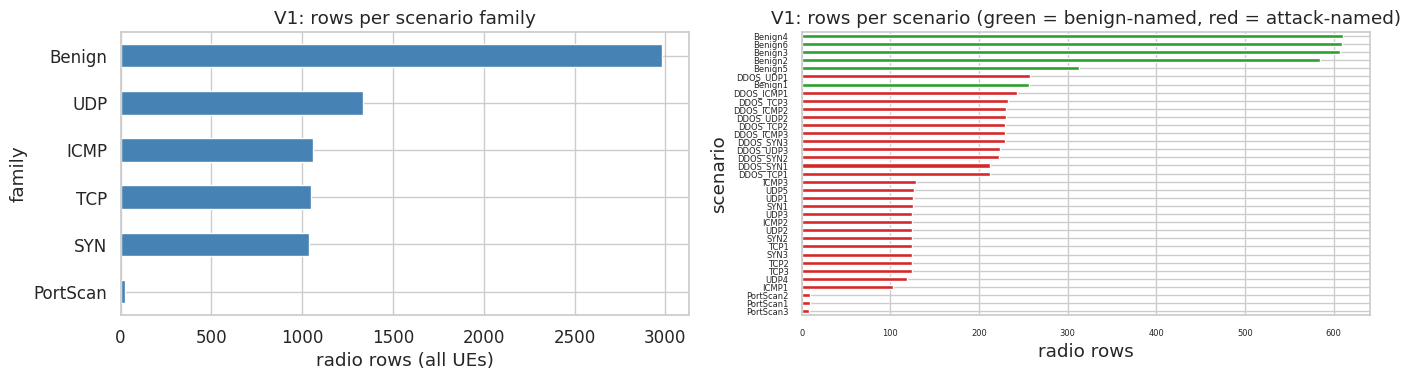

In [63]:
SMALL_ROWS = 30
sm = scn[scn.rows < SMALL_ROWS][["family", "rows", "n_ue", "duration_s"]]
print(f"V1 scenarios with fewer than {SMALL_ROWS} rows (too small for per-scenario statistics / held-out evaluation):"); display(sm)
fam = v1.groupby("family").agg(rows=("ue_id", "size"), scenarios=("scenario", "nunique")); fam["rows_per_scenario"] = (fam.rows / fam.scenarios).round(1); display(fam)
ben_rows = (v1.scenario_class_from_filename == "benign").sum(); print(f"benign rows: {ben_rows:,} ({100*ben_rows/len(v1):.1f}%) from {scn.class_from_filename.eq('benign').sum()} scenarios | attack rows: {len(v1)-ben_rows:,}")
print("benign scenario recording date(s) (UTC):", sorted(scn[scn.class_from_filename == 'benign'].start_utc.dt.date.astype(str).unique()), "| attack scenario dates:", sorted(scn[scn.class_from_filename == 'attack'].start_utc.dt.date.astype(str).unique()))
print("\nimbalance (rows): max/min over families =", round(fam.rows.max() / fam.rows.min(), 1), "| over scenarios =", round(scn.rows.max() / scn.rows.min(), 1))
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
fam.rows.sort_values().plot.barh(ax=ax[0], color="steelblue"); ax[0].set_xlabel("radio rows (all UEs)"); ax[0].set_title("V1: rows per scenario family")
scn.rows.sort_values().plot.barh(ax=ax[1], color=["tab:green" if scn.class_from_filename[i] == "benign" else "tab:red" for i in scn.rows.sort_values().index], fontsize=6)
ax[1].set_xlabel("radio rows"); ax[1].set_title("V1: rows per scenario (green = benign-named, red = attack-named)"); savefig("class_distribution_v1")
FINDINGS.update(v1_small=sm.index.tolist(), v1_benign_scn=int(scn.class_from_filename.eq("benign").sum()))

*What this means for the proposed experiments.* The number of **independent recordings** per family (not the number of rows) is the effective sample size for any generalisation claim. Families with 1–3 recordings, or recordings with fewer than ~30 samples, cannot support multi-class performance claims; the benign class comes from a small number of recordings made on a single day.

---
## 12 · Duplicate Investigation
Nothing is removed. Each category reports counts, columns used, affected scenarios and an evidence-based interpretation.

In [64]:
dup = []
def add_dup(ds, cat, n, total, cols, affected, note):
    dup.append({"dataset": ds, "category": cat, "n_records": int(n), "pct_of_dataset": round(100 * n / max(total, 1), 3), "columns": cols, "affected": affected, "interpretation": note})
N = len(v1)
m = v1.duplicated(subset=["scenario"] + raw_cols, keep=False)
add_dup("V1", "exact duplicate rows within a scenario (all raw columns)", v1.duplicated(subset=["scenario"] + raw_cols).sum(), N, "all raw columns", sorted(v1[m].scenario.unique().tolist())[:10], "")
m2 = v1.duplicated(subset=raw_cols, keep=False)
add_dup("V1", "exact duplicate rows ignoring scenario", v1.duplicated(subset=raw_cols).sum(), N, "all raw columns", sorted(v1[m2].scenario.unique().tolist())[:10], "")
m3 = v1.duplicated(["scenario", "ue_id", "timestamp_ms"], keep=False)
add_dup("V1", "same UE, same timestamp (partial)", v1.duplicated(["scenario", "ue_id", "timestamp_ms"]).sum(), N, "scenario, ue_id, timestamp", sorted(v1[m3].scenario.unique().tolist())[:10], "two samples for one UE at one instant; NOT the same as several UEs sharing a timestamp")
kk = v1[KPIS].astype("float64").round(4).astype(str).agg("|".join, axis=1)
add_dup("V1", "identical KPI vector (14 KPIs), any scenario", kk.duplicated().sum(), N, "14 KPIs", [], "slow-changing radio values naturally repeat; not an error by itself")
sc_per_kpi = v1.groupby(kk).scenario.nunique(); n_cross = int(kk.map(sc_per_kpi).gt(1).sum())
add_dup("V1", "identical KPI vector appearing in >1 scenario", n_cross, N, "14 KPIs", [], "cross-scenario similarity; common for low-variance KPIs")
cls_per_kpi = v1.groupby(kk).scenario_class_from_filename.nunique(); n_conf = int(kk.map(cls_per_kpi).gt(1).sum())
add_dup("V1", "identical KPI vector seen with BOTH benign-named and attack-named scenarios", n_conf, N, "14 KPIs", [], "radio KPIs alone cannot separate these rows")
tup = v1[["timestamp_ms", "ue_id", "dlBytes", "ulBytes"]].astype("float64").astype(str).agg("|".join, axis=1); sc_per_tup = v1.groupby(tup).scenario.nunique()
add_dup("V1", "(timestamp, ue, dlBytes, ulBytes) identical across scenarios", int(tup.map(sc_per_tup).gt(1).sum()), N, "timestamp, ue_id, dlBytes, ulBytes", [], "would indicate the same recording stored in two scenario files")
# csv vs json twins
tw = []
for stem in sorted({p.rsplit('.', 1)[0] for p in glob.glob(f"{ORIG}/*/*.json")}):
    c = pd.read_csv(stem + ".csv", dtype={"rnti": str, "pmi": str}) if os.path.exists(stem + ".csv") else None
    try: j = pd.DataFrame(json.load(open(stem + ".json", errors="replace")))
    except Exception: j = None
    if c is not None and j is not None and "timestamp" in c.columns and "timestamp" in j.columns:
        cc, jj = [x.sort_values(["timestamp", "ue_id"]).reset_index(drop=True) for x in (c, j)]
        same = len(cc) == len(jj) and all(np.allclose(pd.to_numeric(cc[k], errors="coerce"), pd.to_numeric(jj[k], errors="coerce"), equal_nan=True) for k in NUM_COLS + ["timestamp", "ue_id"] if k in cc and k in jj)
        tw.append({"scenario": os.path.basename(stem), "csv_rows": len(c), "json_rows": len(j), "numerically_identical": same})
twins = pd.DataFrame(tw); print("csv vs json twin files:", len(twins), "pairs |", "identical:", int(twins.numerically_identical.sum()) if len(twins) else 0); display(twins[~twins.numerically_identical] if len(twins) else twins)
add_dup("V1", "csv/json twin pairs that are NOT numerically identical", int((~twins.numerically_identical).sum()) if len(twins) else 0, max(len(twins), 1), "all numeric columns", twins[~twins.numerically_identical].scenario.tolist() if len(twins) else [], "csv and json twin should be the same recording")
# overlap source vs aggregates
for r in recon.itertuples():
    add_dup("V1", f"source rows absent from {r.file}", r.v1_rows_absent_from_file, N, r.key_columns, [], "rows dropped when the aggregate was generated")
    add_dup("V1", f"rows of {r.file} not traceable to the source", r.rows_in_file - r.file_rows_traced_to_v1, r.rows_in_file, r.key_columns, [], "values changed or not present in the per-scenario files")
display(pd.DataFrame(dup))

csv vs json twin files: 33 pairs | identical: 33


,scenario,csv_rows,json_rows,numerically_identical


,dataset,category,n_records,pct_of_dataset,columns,affected,interpretation
0,V1,exact duplicate rows within a scenario (all raw columns),35,0.467,all raw columns,"[Benign1, Benign2, Benign3, Benign4, Benign5, Benign6, DDOS_ICMP1, DDOS_ICMP2, DDOS_IC...",
1,V1,exact duplicate rows ignoring scenario,35,0.467,all raw columns,"[Benign1, Benign2, Benign3, Benign4, Benign5, Benign6, DDOS_ICMP1, DDOS_ICMP2, DDOS_IC...",
2,V1,"same UE, same timestamp (partial)",35,0.467,"scenario, ue_id, timestamp","[Benign1, Benign2, Benign3, Benign4, Benign5, Benign6, DDOS_ICMP1, DDOS_ICMP2, DDOS_IC...",two samples for one UE at one instant; NOT the same as several UEs sharing a timestamp
3,V1,"identical KPI vector (14 KPIs), any scenario",117,1.562,14 KPIs,[],slow-changing radio values naturally repeat; not an error by itself
4,V1,identical KPI vector appearing in >1 scenario,0,0.000,14 KPIs,[],cross-scenario similarity; common for low-variance KPIs
5,V1,identical KPI vector seen with BOTH benign-named and attack-named scenarios,0,0.000,14 KPIs,[],radio KPIs alone cannot separate these rows
6,V1,"(timestamp, ue, dlBytes, ulBytes) identical across scenarios",0,0.000,"timestamp, ue_id, dlBytes, ulBytes",[],would indicate the same recording stored in two scenario files
7,V1,csv/json twin pairs that are NOT numerically identical,0,0.000,all numeric columns,[],csv and json twin should be the same recording
8,V1,source rows absent from cleaned_radio_telemetry.csv,253,3.378,"cqi,dlBler,dlBytes,ulBytes,rsrp,rssi,sinr,dlMcs,ulMcs,phr",[],rows dropped when the aggregate was generated
9,V1,rows of cleaned_radio_telemetry.csv not traceable to the source,0,0.000,"cqi,dlBler,dlBytes,ulBytes,rsrp,rssi,sinr,dlMcs,ulMcs,phr",[],values changed or not present in the per-scenario files


In [65]:
# newer release ------------------------------------------------------------------------------------------------------------------------
NN = len(nwt); dcols = [c for c in db_cols]
add_dup("newer", "exact duplicate rows (all original columns)", nw.duplicated(subset=dcols).sum(), NN, "all DB columns", [], "")
add_dup("newer", "same UE, same timestamp within a recording", nwt.duplicated(["recording_id", "ue_id", "timestamp_ms"]).sum(), NN, "recording_id, ue_id, timestamp", [], "recording id is traced/reconstructed")
kkn = nwt[KPIS].astype("float64").round(4).astype(str).agg("|".join, axis=1)
add_dup("newer", "identical KPI vector, any recording", kkn.duplicated().sum(), NN, "14 KPIs", [], "")
cn = nwt.groupby(kkn).binary_group.nunique(); add_dup("newer", "identical KPI vector seen with both benign and attack rows", int(kkn.map(cn).gt(1).sum()), NN, "14 KPIs", [], "")
tupn = nwt[["timestamp_ms", "ue_id", "dlBytes", "ulBytes"]].astype("float64").astype(str).agg("|".join, axis=1); rn = nwt.groupby(tupn).recording_id.nunique()
add_dup("newer", "(timestamp, ue, dlBytes, ulBytes) identical across recordings", int(tupn.map(rn).gt(1).sum()), NN, "timestamp, ue_id, dlBytes, ulBytes", [], "same sample stored under two recordings / categories")
if "raw_key_dupes" in nw_stats: add_dup("newer", "duplicate keys inside the raw txt files", nw_stats["raw_key_dupes"], nw_stats["raw_rows"], "timestamp, ue_id, dlBytes, ulBytes", [], "")
add_dup("newer", "DB rows not traceable to any raw file", NN - nw_stats["db_rows_traced_to_raw"], NN, "timestamp, ue_id, dlBytes, ulBytes", [], "recording id for these rows is RECONSTRUCTED")
if "raw_rows_not_in_db" in nw_stats: add_dup("newer", "raw rows missing from the DB", nw_stats["raw_rows_not_in_db"], nw_stats["raw_rows_keyed"], "timestamp, ue_id, dlBytes, ulBytes", list(nw_stats["raw_missing_by_file"])[:10], "")
dup_df = pd.DataFrame(dup); save_csv(dup_df, "duplicate_analysis.csv"); display(dup_df[dup_df.dataset == "newer"])

saved: /kaggle/working/analysis/radio_outputs/duplicate_analysis.csv (20, 7)


,dataset,category,n_records,pct_of_dataset,columns,affected,interpretation
12,newer,exact duplicate rows (all original columns),0,0.000,all DB columns,[],
13,newer,"same UE, same timestamp within a recording",220,0.486,"recording_id, ue_id, timestamp",[],recording id is traced/reconstructed
14,newer,"identical KPI vector, any recording",1323,2.924,14 KPIs,[],
15,newer,identical KPI vector seen with both benign and attack rows,0,0.000,14 KPIs,[],
16,newer,"(timestamp, ue, dlBytes, ulBytes) identical across recordings",0,0.000,"timestamp, ue_id, dlBytes, ulBytes",[],same sample stored under two recordings / categories
17,newer,duplicate keys inside the raw txt files,0,0.000,"timestamp, ue_id, dlBytes, ulBytes",[],
18,newer,DB rows not traceable to any raw file,1540,3.404,"timestamp, ue_id, dlBytes, ulBytes",[],recording id for these rows is RECONSTRUCTED
19,newer,raw rows missing from the DB,748,1.683,"timestamp, ue_id, dlBytes, ulBytes",[tcp_npig],


---
## 13 · Data Leakage Investigation
Every row of `leakage_analysis.csv` is backed by a number computed in this notebook. Association metrics (no model is trained):

* **discrete columns** (≤ 60 distinct values): *scenario purity* = how well the value alone identifies the scenario by lookup; *unique share* = fraction of distinct values that occur in only one scenario;
* **continuous columns**: Kruskal–Wallis ε² (share of variance explained by scenario membership).
Severity: HIGH ≥ 0.9, MEDIUM ≥ 0.6, otherwise LOW. KPIs are listed too, but a high value for a KPI is **not** proof of leakage — a KPI can differ between scenarios for genuine or for recording-specific reasons; §14 compares the two.

In [66]:
def assoc(df, col, grp):
    s = df[col]; nun = s.nunique(dropna=True)
    if nun <= 1: return "constant", np.nan, np.nan, np.nan
    base = df[grp].value_counts(normalize=True).iloc[0]
    if nun <= 60:
        ct = pd.crosstab(s.astype(str), df[grp]); return "discrete", ct.max(axis=1).sum() / ct.values.sum(), (ct.gt(0).sum(axis=1) == 1).mean(), base
    num = pd.to_numeric(s, errors="coerce")
    if num.notna().mean() < .9: return "text", np.nan, np.nan, base
    grs = [num[df[grp] == k].dropna().values for k in df[grp].unique()]; grs = [x for x in grs if len(x)]
    try: H = stats.kruskal(*grs).statistic
    except ValueError: return "continuous", np.nan, np.nan, base
    return "continuous", min(max(H / (sum(len(x) for x in grs) - 1), 0), 1), np.nan, base

def sev(m): return "n/a" if pd.isna(m) else "HIGH" if m >= .9 else "MEDIUM" if m >= .6 else "LOW"
LEAK = []
def leak_rows(df, ds, scn_col, cls_col, cols, category_of):
    for c in cols:
        if c not in df.columns: continue
        kind, m_s, uniq, base = assoc(df, c, scn_col); _, m_c, _, base_c = assoc(df, c, cls_col)
        confirmed = kind == "discrete" and ((uniq if pd.notna(uniq) else 0) >= .95 or (m_s if pd.notna(m_s) else 0) >= .99)
        LEAK.append({"dataset": ds, "column": c, "category": category_of.get(c, "KPI (signal vs recording fingerprint not separable here)"), "kind": kind,
                     "assoc_with_scenario": m_s, "assoc_with_class": m_c, "unique_to_one_scenario_share": uniq, "scenario_baseline_majority_share": base,
                     "severity": "n/a (constant)" if kind == "constant" else sev(m_s), "status": "confirmed" if confirmed else "potential (statistical association only)",
                     "evidence": f"{kind}: association with scenario = {m_s:.3f}" + (f", unique-to-one-scenario share = {uniq:.3f}" if pd.notna(uniq) else "") if pd.notna(m_s) else kind})
CAT = {"ue_id": "identifier", "rnti_int": "identifier", "cellid": "identifier", "in_sync": "status flag", "timestamp_ms": "temporal", "dlBytes": "cumulative counter (position in recording)", "ulBytes": "cumulative counter (position in recording)",
       "file_row": "row order in file"}
v1["file_row_pos"] = v1.groupby("scenario").file_row.transform(lambda s: s / max(len(s) - 1, 1))
leak_rows(v1, "V1", "scenario", "scenario_class_from_filename", ["ue_id", "rnti_int", "cellid", "in_sync", "timestamp_ms", "dlBytes", "ulBytes"] + KPIS + ["pmi_0", "pmi_1"], CAT)
leak = pd.DataFrame(LEAK); display(leak.sort_values("assoc_with_scenario", ascending=False).round(3)[["column", "category", "kind", "assoc_with_scenario", "assoc_with_class", "unique_to_one_scenario_share", "severity", "status"]])

,column,category,kind,assoc_with_scenario,assoc_with_class,unique_to_one_scenario_share,severity,status
4,timestamp_ms,temporal,continuous,0.997,0.719,NaN,HIGH,potential (statistical association only)
5,dlBytes,cumulative counter (position in recording),continuous,0.884,0.217,NaN,MEDIUM,potential (statistical association only)
8,rssi,KPI (signal vs recording fingerprint not separable here),continuous,0.726,0.218,NaN,MEDIUM,potential (statistical association only)
6,ulBytes,cumulative counter (position in recording),continuous,0.719,0.075,NaN,MEDIUM,potential (statistical association only)
14,dlBler,KPI (signal vs recording fingerprint not separable here),continuous,0.550,0.104,NaN,LOW,potential (statistical association only)
1,rnti_int,identifier,discrete,0.417,1.000,0.636,LOW,potential (statistical association only)
0,ue_id,identifier,discrete,0.350,0.983,0.286,LOW,potential (statistical association only)
7,rsrp,KPI (signal vs recording fingerprint not separable here),discrete,0.219,0.771,0.132,LOW,potential (statistical association only)
10,sinr,KPI (signal vs recording fingerprint not separable here),discrete,0.178,0.825,0.050,LOW,potential (statistical association only)
12,dlMcs,KPI (signal vs recording fingerprint not separable here),discrete,0.177,0.763,0.115,LOW,potential (statistical association only)


In [67]:
# structural (non-statistical) findings with computed evidence ---------------------------------------------------------------------------------------
S = []
def srow(ds, col, cat, ev, sev_, st, who, handling): S.append({"dataset": ds, "column": col, "category": cat, "evidence": ev, "severity": sev_, "status": st, "affected": who, "recommended_handling": handling})
# 1 label columns
srow("V1 per-scenario", "(no label column)", "label availability", f"label-like columns present in the files: {[c for c in raw_cols if 'label' in c.lower() or 'traffic' in c.lower() or 'attack' in c.lower()] or 'none'}; scenario = file name", "INFO", "confirmed", "all", "scenario-level labels must be attached from the file name; keep file name as metadata, never as a feature")
# 2 cellid vs DDOS
ct_c = pd.crosstab(v1.loc[v1.scenario_class_from_filename == "attack", "ddos"], v1.loc[v1.scenario_class_from_filename == "attack", "cellid"])
if ct_c.shape[1] > 1 and (ct_c.gt(0).sum(axis=1) == 1).all():
    srow("V1 per-scenario", "cellid", "identifier leakage", f"cellid values by DDOS flag (attack scenarios): {ct_c.to_dict()} - each value occurs for exactly one flag; benign cellid values: {sorted(v1.loc[v1.scenario_class_from_filename=='benign','cellid'].unique().astype(int).tolist())}", "HIGH", "confirmed", "DDOS_* scenarios", "keep for alignment metadata only; exclude from model features")
# 3 file order direction vs class
fo_ct = pd.crosstab(scn.class_from_filename, scn.file_order_desc)
if fo_ct.shape[1] > 1:
    srow("V1 per-scenario", "row order in file", "ordering leakage", f"stored newest-first by class: {fo_ct.to_dict()}", "HIGH" if (fo_ct.gt(0).sum(axis=1) == 1).all() else "MEDIUM", "confirmed" if (fo_ct.gt(0).sum(axis=1) == 1).all() else "potential", "see table", "never use row position/order as a feature or split key; always sort by timestamp")
# 4 disjoint time
srow("V1 per-scenario", "timestamp", "temporal leakage", f"scenario time ranges overlap: {bool((scn.sort_values('start_utc').start_utc.iloc[1:].values < scn.sort_values('start_utc').end_utc.iloc[:-1].values).any())}; every timestamp belongs to exactly one scenario if ranges are disjoint", "HIGH", "confirmed", "all", "keep for alignment only; absolute time identifies the recording")
# 5 rnti
srow("V1 per-scenario", "rnti", "identifier leakage", f"{(scn_per_rnti == 1).mean():.1%} of distinct rnti values occur in a single scenario ({v1.rnti.map(scn_per_rnti).eq(1).mean():.1%} of rows)", sev(v1.rnti.map(scn_per_rnti).eq(1).mean()), "confirmed" if v1.rnti.map(scn_per_rnti).eq(1).mean() >= .95 else "potential (statistical association only)", "all", "exclude from features; keep for audit")
# 6 aggregated files
for r in recon.itertuples():
    srow("V1 aggregates", r.file, "derived artefact", f"{r.rows_in_file:,} rows vs {r.rows_in_v1_per_scenario:,} source rows; traced {r.traced_pct}%; source rows absent {r.v1_rows_absent_from_file:,}; no timestamp/ue/scenario columns", "MEDIUM", "confirmed", "all", "do not use for alignment; reconcile before any use; rnti/pmi are re-encoded")
# 7 newer release labels
for c in [x for x in ["traffic_type", "attack_category", "attack_subcategory"] if x in nw.columns]:
    srow("newer DB", c, "target / label column inside the data table", f"present as a column of lower_layer_data; attack_subcategory distinct values = {nw.attack_subcategory.nunique() if 'attack_subcategory' in nw.columns else 'n/a'} (encodes the scenario/attack type)", "CRITICAL", "confirmed", "all rows", "labels, never features")
srow("newer DB", "recording id", "metadata gap", f"no recording id in the processed table; {nw_stats['db_rows_traced_to_raw']:,}/{nw_stats['db_rows']:,} rows traced to raw files, the rest use RECONSTRUCTED time-gap segments", "HIGH", "confirmed", "untraced rows", "group splits by recording require a verified id; do not trust reconstructed ids silently")
leak_n = []
LEAK.clear(); leak_rows(nwt, "newer", "recording_id", "binary_group", ["ue_id", "rnti_int", "cellid", "in_sync", "timestamp_ms", "dlBytes", "ulBytes"] + KPIS, CAT)
leak_n = pd.DataFrame(LEAK)
leakage_analysis = pd.concat([leak.assign(recommended_handling="exclude identifiers/time/counters from features; KPIs: see §14"), pd.DataFrame(S), leak_n.assign(recommended_handling="same as V1")], ignore_index=True)
save_csv(leakage_analysis, "leakage_analysis.csv")
display(pd.DataFrame(S)[["dataset", "column", "category", "severity", "status", "evidence"]])
display(leak_n.sort_values("assoc_with_scenario", ascending=False).round(3)[["column", "kind", "assoc_with_scenario", "assoc_with_class", "unique_to_one_scenario_share", "severity", "status"]].head(12))

saved: /kaggle/working/analysis/radio_outputs/leakage_analysis.csv (55, 13)


,dataset,column,category,severity,status,evidence
0,V1 per-scenario,(no label column),label availability,INFO,confirmed,label-like columns present in the files: none; scenario = file name
1,V1 per-scenario,cellid,identifier leakage,HIGH,confirmed,"cellid values by DDOS flag (attack scenarios): {11111111: {0: 1753, 1: 0}, 12345678: {..."
2,V1 per-scenario,row order in file,ordering leakage,MEDIUM,potential,"stored newest-first by class: {False: {'attack': 9, 'benign': 0}, True: {'attack': 20,..."
3,V1 per-scenario,timestamp,temporal leakage,HIGH,confirmed,scenario time ranges overlap: False; every timestamp belongs to exactly one scenario i...
4,V1 per-scenario,rnti,identifier leakage,LOW,potential (statistical association only),63.6% of distinct rnti values occur in a single scenario (11.3% of rows)
5,V1 aggregates,cleaned_radio_telemetry.csv,derived artefact,MEDIUM,confirmed,"7,237 rows vs 7,490 source rows; traced 100.0%; source rows absent 253; no timestamp/u..."
6,V1 aggregates,after_analysis_radio_telemetry.csv,derived artefact,MEDIUM,confirmed,"7,237 rows vs 7,490 source rows; traced 100.0%; source rows absent 253; no timestamp/u..."
7,newer DB,traffic_type,target / label column inside the data table,CRITICAL,confirmed,present as a column of lower_layer_data; attack_subcategory distinct values = 19 (enco...
8,newer DB,attack_category,target / label column inside the data table,CRITICAL,confirmed,present as a column of lower_layer_data; attack_subcategory distinct values = 19 (enco...
9,newer DB,attack_subcategory,target / label column inside the data table,CRITICAL,confirmed,present as a column of lower_layer_data; attack_subcategory distinct values = 19 (enco...


,column,kind,assoc_with_scenario,assoc_with_class,unique_to_one_scenario_share,severity,status
4,timestamp_ms,continuous,0.997,0.168,NaN,HIGH,potential (statistical association only)
10,sinr,continuous,0.725,0.185,NaN,MEDIUM,potential (statistical association only)
6,ulBytes,continuous,0.701,0.041,NaN,MEDIUM,potential (statistical association only)
5,dlBytes,continuous,0.668,0.020,NaN,MEDIUM,potential (statistical association only)
1,rnti_int,discrete,0.614,0.981,0.500,MEDIUM,potential (statistical association only)
15,ulBler,continuous,0.508,0.163,NaN,LOW,potential (statistical association only)
14,dlBler,continuous,0.483,0.144,NaN,LOW,potential (statistical association only)
0,ue_id,discrete,0.239,0.865,0.333,LOW,potential (statistical association only)
7,rsrp,discrete,0.223,0.894,0.097,LOW,potential (statistical association only)
8,rssi,continuous,0.197,0.000,NaN,LOW,potential (statistical association only)


---
## 14 · Scenario Predictability Analysis (lightweight, clearly separated)
> **Objective:** *scenario identification*, **not** attack detection. A shallow decision tree is asked to name the **scenario/recording** from different column groups. High scores mean those columns carry scenario-specific signatures — the dataset can then be solved by recognising recordings instead of attacks.
>
> **Method:** depth-3 and depth-10 decision trees (no tuning, no feature selection), 5 folds, two evaluation schemes:
> *random* (rows shuffled — adjacent seconds of one recording land in train and test) vs *blocked* (each scenario is cut into 5 contiguous time blocks; one block per scenario is held out). The gap between them measures how much of the score comes from temporal autocorrelation inside a recording.
> **Limitations:** small data, one UE-row granularity, trees only, timestamp excluded on purpose (absolute time trivially identifies a recording). No attack/benign classifier is trained here.

In [68]:
def blocked_folds(df, scen_col, k=5):
    d = df.sort_values("timestamp_ms"); rank = d.groupby(scen_col).cumcount(); n = d.groupby(scen_col)[scen_col].transform("size")
    return np.minimum((rank * k // n).astype(int), k - 1).reindex(df.index).values

def run_cv(X, y, folds, depth):
    pred = np.full(len(y), -1); m = DecisionTreeClassifier(max_depth=depth, random_state=0)
    for f in np.unique(folds):
        te = folds == f; pred[te] = clone(m).fit(X[~te], y[~te]).predict(X[te])
    return accuracy_score(y, pred), f1_score(y, pred, average="macro"), pred

def predictability(df, scen_col, groups, ds, max_rows=40000):
    d = df.dropna(subset=["timestamp_ms"]).copy()
    if len(d) > max_rows: d = d.sample(max_rows, random_state=0)
    y_raw = d[scen_col].values; classes, y = np.unique(y_raw, return_inverse=True); base = np.bincount(y).max() / len(y)
    blocked = blocked_folds(d, scen_col, 5); rnd = np.random.RandomState(0).randint(0, 5, len(d))
    out, preds = [], {}
    for gname, cols in groups.items():
        cols = [c for c in cols if c in d.columns]
        X = d[cols].apply(pd.to_numeric, errors="coerce").fillna(-1e9).values
        for depth in (3, 10):
            for scheme, folds in [("random rows", rnd), ("blocked in time", blocked)]:
                acc, f1, pr = run_cv(X, y, folds, depth)
                out.append({"dataset": ds, "task": f"scenario identification ({len(classes)} classes)", "feature_group": gname, "n_features": len(cols), "tree_depth": depth, "cv_scheme": scheme,
                            "accuracy": acc, "macro_f1": f1, "majority_baseline": base, "rows": len(d)})
                preds[(gname, depth, scheme)] = (pr, y)
    return pd.DataFrame(out), classes, preds

G_V1 = {"KPIs only": KPIS, "identifiers only (ue_id, rnti, cellid, in_sync)": ["ue_id", "rnti_int", "cellid", "in_sync"], "raw byte counters only": COUNTERS,
        "KPIs + identifiers + counters": KPIS + ["ue_id", "rnti_int", "cellid", "in_sync"] + COUNTERS}
pred_v1, cls_v1, preds_v1 = predictability(v1, "scenario", G_V1, "V1")
display(pred_v1.pivot_table(index=["feature_group", "tree_depth"], columns="cv_scheme", values=["accuracy", "macro_f1"]).round(3))
print(f"majority-class baseline (always guess the largest scenario) = {pred_v1.majority_baseline.iloc[0]:.3f}")

accuracy                    macro_f1            
cv_scheme                                                  blocked in time random rows blocked in time random rows
feature_group                                   tree_depth                                                        
KPIs + identifiers + counters                   3                    0.310       0.324           0.133       0.151
                                                10                   0.930       0.967           0.926       0.950
KPIs only                                       3                    0.209       0.223           0.094       0.104
                                                10                   0.429       0.554           0.414       0.527
identifiers only (ue_id, rnti, cellid, in_sync) 3                    0.251       0.235           0.111       0.138
                                                10                   0.411       0.389           0.284       0.328
raw byte counters only                          3                    0.281       0.318           0.114       0.132
                                                10                   0.730       0.857           0.729       0.845

majority-class baseline (always guess the largest scenario) = 0.082


,recall,samples,family,class_from_filename
scenario,,,,
DDOS_UDP1,0.671,258,UDP,attack
UDP2,0.648,125,UDP,attack
UDP4,0.639,119,UDP,attack
DDOS_ICMP2,0.602,231,ICMP,attack
TCP1,0.568,125,TCP,attack
DDOS_SYN2,0.561,223,SYN,attack
Benign6,0.534,609,Benign,benign
DDOS_SYN3,0.528,229,SYN,attack
DDOS_TCP2,0.511,229,TCP,attack


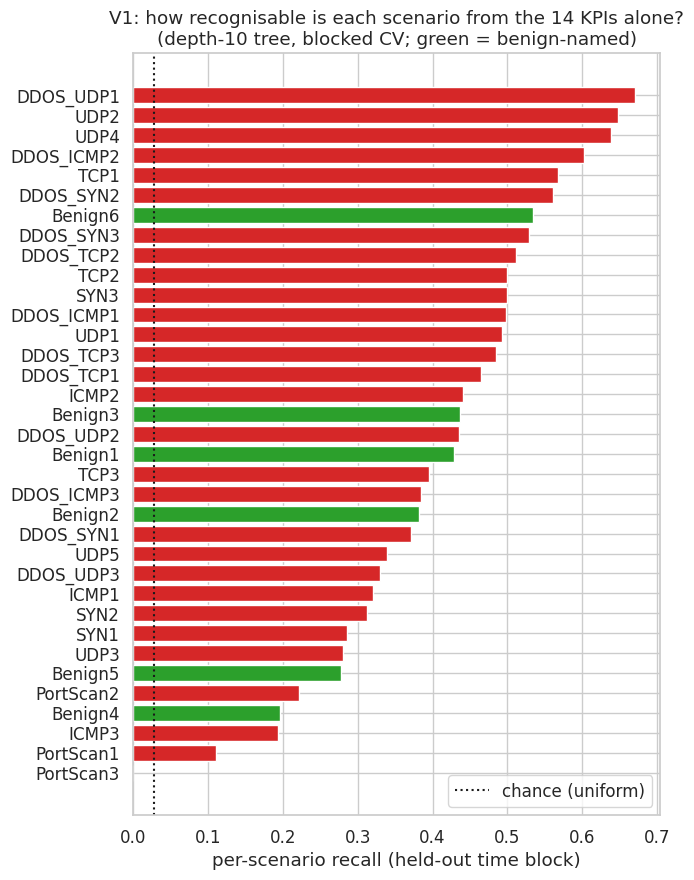

scenarios with recall >= 0.8: []


In [69]:
# which V1 scenarios are individually recognisable from KPIs alone (depth 10, blocked) ---------------------------------------------------------
pr, y = preds_v1[("KPIs only", 10, "blocked in time")]
rec = pd.DataFrame({"scenario": cls_v1[y], "ok": pr == y}).groupby("scenario").ok.agg(recall="mean", samples="size")
rec = rec.join(scn[["family", "class_from_filename"]]).sort_values("recall", ascending=False); display(rec.round(3))
fig, ax = plt.subplots(figsize=(7, 9)); rr = rec.sort_values("recall")
ax.barh(rr.index, rr.recall, color=["tab:green" if c == "benign" else "tab:red" for c in rr.class_from_filename]); ax.set_xlabel("per-scenario recall (held-out time block)")
ax.set_title("V1: how recognisable is each scenario from the 14 KPIs alone?\n(depth-10 tree, blocked CV; green = benign-named)"); ax.axvline(1 / len(cls_v1), color="k", ls=":", label="chance (uniform)"); ax.legend(); savefig("scenario_recall_kpi_v1")
print("scenarios with recall >= 0.8:", rec[rec.recall >= .8].index.tolist())

In [70]:
G_NW = {"KPIs only": KPIS, "identifiers only (ue_id, rnti, cellid, in_sync)": ["ue_id", "rnti_int", "cellid", "in_sync"], "raw byte counters only": COUNTERS,
        "KPIs + identifiers + counters": KPIS + ["ue_id", "rnti_int", "cellid", "in_sync"] + COUNTERS}
pred_nw, cls_nw, preds_nw = predictability(nwt, "recording_id", G_NW, "newer")
display(pred_nw.pivot_table(index=["feature_group", "tree_depth"], columns="cv_scheme", values=["accuracy", "macro_f1"]).round(3))
print(f"majority baseline = {pred_nw.majority_baseline.iloc[0]:.3f} | classes = recordings (traced file names; untraced rows use reconstructed segments - interpret with care)")
pred_report = pd.concat([pred_v1, pred_nw], ignore_index=True); save_csv(pred_report, "scenario_predictability_report.csv")

accuracy                    macro_f1            
cv_scheme                                                  blocked in time random rows blocked in time random rows
feature_group                                   tree_depth                                                        
KPIs + identifiers + counters                   3                    0.262       0.288           0.076       0.086
                                                10                   0.718       0.848           0.628       0.693
KPIs only                                       3                    0.188       0.213           0.072       0.062
                                                10                   0.419       0.497           0.316       0.391
identifiers only (ue_id, rnti, cellid, in_sync) 3                    0.259       0.275           0.065       0.050
                                                10                   0.598       0.612           0.371       0.386
raw byte counters only                          3                    0.213       0.267           0.085       0.092
                                                10                   0.534       0.764           0.489       0.610

majority baseline = 0.125 | classes = recordings (traced file names; untraced rows use reconstructed segments - interpret with care)
saved: /kaggle/working/analysis/radio_outputs/scenario_predictability_report.csv (32, 10)


In [71]:
k = pred_v1[(pred_v1.tree_depth == 10)].pivot_table(index="feature_group", columns="cv_scheme", values="accuracy")
print("Computed reading (V1, depth-10 tree):")
for g, r in k.iterrows(): print(f"  {g:55s} random rows: {r['random rows']:.2f} | blocked in time: {r['blocked in time']:.2f} | gap: {r['random rows'] - r['blocked in time']:+.2f}")
print("\nA large gap means most of the apparent predictability comes from neighbouring seconds of the same recording (temporal autocorrelation).")
print("Scores far above the baseline for 'identifiers only' or 'counters only' show that these columns identify recordings; they are not evidence about attacks.")
print("Combined Network + Radio scenario distinguishability cannot be measured in this notebook (it needs the network side and a verified alignment).")

Computed reading (V1, depth-10 tree):
  KPIs + identifiers + counters                           random rows: 0.97 | blocked in time: 0.93 | gap: +0.04
  KPIs only                                               random rows: 0.55 | blocked in time: 0.43 | gap: +0.13
  identifiers only (ue_id, rnti, cellid, in_sync)         random rows: 0.39 | blocked in time: 0.41 | gap: -0.02
  raw byte counters only                                  random rows: 0.86 | blocked in time: 0.73 | gap: +0.13

A large gap means most of the apparent predictability comes from neighbouring seconds of the same recording (temporal autocorrelation).
Scores far above the baseline for 'identifiers only' or 'counters only' show that these columns identify recordings; they are not evidence about attacks.
Combined Network + Radio scenario distinguishability cannot be measured in this notebook (it needs the network side and a verified alignment).


---
## 15 · Radio Dataset Limitations
Every bullet is generated from numbers computed above.

In [72]:
L = []
rc = recon.iloc[0].to_dict() if len(recon) else {}
L.append(("CRITICAL", "The V1 radio database is empty and the aggregated csv files carry no time, UE or scenario", f"5G-NL-IDD_Radio_Telemetry.db = {FINDINGS['v1_db_size']} bytes; aggregates have {', '.join(f'{k}: {len(v):,} rows x {v.shape[1]} cols' for k, v in AGG.items())}", "Only the per-scenario files can support time-based or scenario-level work"))
if rc: L.append(("HIGH", "Aggregated csv is not a faithful copy of the source", f"{rc['file']}: {rc['rows_in_file']:,} rows vs {rc['rows_in_v1_per_scenario']:,} source rows; traced {rc['traced_pct']}%; source rows absent {rc['v1_rows_absent_from_file']:,}", "Reconcile before any use; do not mix rows of the aggregate with per-scenario metadata"))
L.append(("HIGH", "Few independent recordings", f"V1: {FINDINGS['v1_scenarios']} scenarios, {FINDINGS['v1_benign_scn']} benign; scenarios under 30 rows: {FINDINGS['v1_small']}", "Effective sample size is the number of recordings, not rows; no strong multi-class claims"))
L.append(("HIGH", "Benign and attack data come from different recordings/days", f"benign dates {sorted(scn[scn.class_from_filename=='benign'].start_utc.dt.date.astype(str).unique())}; attack dates {sorted(scn[scn.class_from_filename=='attack'].start_utc.dt.date.astype(str).unique())[:6]}...", "Pooled benign-vs-attack KPI differences are confounded by recording conditions"))
L.append(("HIGH", "Identifiers, time and counters identify the recording", f"see §13/§14 (identifiers-only blocked accuracy {pred_v1[(pred_v1.feature_group.str.startswith('identifiers')) & (pred_v1.tree_depth==10) & (pred_v1.cv_scheme=='blocked in time')].accuracy.iloc[0]:.2f} vs baseline {pred_v1.majority_baseline.iloc[0]:.2f})", "Keep as metadata for alignment/audit only"))
L.append(("MEDIUM", "Labels are scenario-level", "V1 files have no label column; class derived from file name", "Do not treat every sample in an attack scenario as an attack sample"))
L.append(("MEDIUM", "Inconsistent row order between files", f"newest-first files: {sorted(v1.loc[v1.file_order_desc,'scenario'].unique().tolist())}", "Always sort by timestamp; never rely on file order"))
L.append(("MEDIUM", "Byte counters are cumulative per UE series", f"monotonic series share {FINDINGS['bytes_monotonic_share']}", "Use per-interval deltas computed per (recording, UE) in time order — in a later stage"))
L.append(("MEDIUM", "Newer-release recording id is partly reconstructed", f"{nw_stats['db_rows_traced_to_raw']:,}/{nw_stats['db_rows']:,} rows traced to raw files", "Verify before using recordings as split groups"))
L.append(("INFO", "Sampling", f"median step per UE {FINDINGS['v1_median_step']:.0f} ms; {100*FINDINGS['v1_step1000']:.1f}% of steps exactly 1000 ms; UEs per scenario 1-3", "Radio resolution is 1 Hz per UE; sub-second alignment impossible"))
lim = pd.DataFrame(L, columns=["severity", "limitation", "evidence", "implication"]); pd.set_option("display.max_colwidth", 200); display(lim)

,severity,limitation,evidence,implication
0,CRITICAL,"The V1 radio database is empty and the aggregated csv files carry no time, UE or scenario","5G-NL-IDD_Radio_Telemetry.db = 0 bytes; aggregates have cleaned_radio_telemetry.csv: 7,237 rows x 19 cols, after_analysis_radio_telemetry.csv: 7,237 rows x 15 cols",Only the per-scenario files can support time-based or scenario-level work
1,HIGH,Aggregated csv is not a faithful copy of the source,"cleaned_radio_telemetry.csv: 7,237 rows vs 7,490 source rows; traced 100.0%; source rows absent 253",Reconcile before any use; do not mix rows of the aggregate with per-scenario metadata
2,HIGH,Few independent recordings,"V1: 35 scenarios, 6 benign; scenarios under 30 rows: ['PortScan1', 'PortScan2', 'PortScan3']","Effective sample size is the number of recordings, not rows; no strong multi-class claims"
3,HIGH,Benign and attack data come from different recordings/days,"benign dates ['2025-04-14']; attack dates ['2025-02-27', '2025-03-06', '2025-04-03']...",Pooled benign-vs-attack KPI differences are confounded by recording conditions
4,HIGH,"Identifiers, time and counters identify the recording",see §13/§14 (identifiers-only blocked accuracy 0.41 vs baseline 0.08),Keep as metadata for alignment/audit only
5,MEDIUM,Labels are scenario-level,V1 files have no label column; class derived from file name,Do not treat every sample in an attack scenario as an attack sample
6,MEDIUM,Inconsistent row order between files,"newest-first files: ['Benign1', 'Benign2', 'Benign3', 'Benign4', 'Benign5', 'Benign6', 'DDOS_UDP1', 'DDOS_UDP2', 'DDOS_UDP3', 'ICMP1', 'ICMP2', 'ICMP3', 'PortScan1', 'PortScan2', 'PortScan3', 'SYN...",Always sort by timestamp; never rely on file order
7,MEDIUM,Byte counters are cumulative per UE series,"monotonic series share {'dlBytes': 0.85, 'ulBytes': 0.85}","Use per-interval deltas computed per (recording, UE) in time order — in a later stage"
8,MEDIUM,Newer-release recording id is partly reconstructed,"43,704/45,244 rows traced to raw files",Verify before using recordings as split groups
9,INFO,Sampling,median step per UE 1000 ms; 91.4% of steps exactly 1000 ms; UEs per scenario 1-3,Radio resolution is 1 Hz per UE; sub-second alignment impossible


### Unresolved questions that need a human decision
1. Meaning of `traffic_type` in the aggregated csv files (resolved only by row tracing in §5; confirm with the dataset owners).
2. Whether the rows missing from the aggregates were intentionally filtered and why.
3. Whether the newer-release recordings correspond to the network captures at all (not testable from radio data alone).
4. Whether reconstructed (time-gap) recording ids are acceptable as grouping keys for the newer release.

---
## 16 · Summary and Findings

In [73]:
print("=" * 78, "\nRADIO DATASET ANALYSIS - SUMMARY (all numbers computed in this run)\n" + "=" * 78)
print(f"V1 per-scenario radio : {FINDINGS['v1_rows']:,} rows, {FINDINGS['v1_scenarios']} scenarios ({FINDINGS['v1_benign_scn']} benign-named), epoch-ms timestamps, ~1 Hz per UE")
print(f"V1 radio database     : {FINDINGS['v1_db_size']} bytes -> {'EMPTY' if FINDINGS['v1_db_size'] == 0 else 'has content'}")
for r in FINDINGS["agg_recon"]:
    print(f"{r['file']}: {r['rows_in_file']:,} rows, traced to source {r['traced_pct']}%, source rows absent {r['v1_rows_absent_from_file']:,}")
print(f"Newer release         : {FINDINGS['nw_rows']:,} DB rows, {FINDINGS['nw_traced']:,} traced to raw files")
print("\nTop leakage evidence (assoc. with scenario, V1):"); print(leak.sort_values("assoc_with_scenario", ascending=False).head(6)[["column", "assoc_with_scenario", "severity", "status"]].round(3).to_string(index=False))
print("\nPredictability (V1, depth 10, blocked in time):"); print(pred_v1[(pred_v1.tree_depth == 10) & (pred_v1.cv_scheme == "blocked in time")][["feature_group", "accuracy", "macro_f1", "majority_baseline"]].round(3).to_string(index=False))
print("\nNot done on purpose: cleaning, dedup, feature removal/selection, scaling, resampling, splitting, fusion, label correction, attack classification.")

RADIO DATASET ANALYSIS - SUMMARY (all numbers computed in this run)
V1 per-scenario radio : 7,490 rows, 35 scenarios (6 benign-named), epoch-ms timestamps, ~1 Hz per UE
V1 radio database     : 0 bytes -> EMPTY
cleaned_radio_telemetry.csv: 7,237 rows, traced to source 100.0%, source rows absent 253
after_analysis_radio_telemetry.csv: 7,237 rows, traced to source 100.0%, source rows absent 253
Newer release         : 45,244 DB rows, 43,704 traced to raw files

Top leakage evidence (assoc. with scenario, V1):
      column  assoc_with_scenario severity                                   status
timestamp_ms                0.997     HIGH potential (statistical association only)
     dlBytes                0.884   MEDIUM potential (statistical association only)
        rssi                0.726   MEDIUM potential (statistical association only)
     ulBytes                0.719   MEDIUM potential (statistical association only)
      dlBler                0.550      LOW potential (statistical as

In [74]:
# QA: inputs untouched, outputs listed ---------------------------------------------------------------------------------------------------------------------------------
FP_AFTER = _fp(INPUT_FILES)
changed = [p for p in FP_BEFORE if FP_BEFORE[p] != FP_AFTER.get(p)]; added = [p for p in FP_AFTER if p not in FP_BEFORE]
print(f"input files checked: {len(FP_BEFORE)} | changed: {len(changed)} | new: {len(added)}", "-> ORIGINAL DATA UNMODIFIED" if not changed and not added else changed + added)
assert not changed and not added, "input data changed!"
man = pd.DataFrame([{"file": os.path.relpath(p, OUT_ROOT), "bytes": os.path.getsize(p)} for p in OUTPUTS + FIGS if os.path.exists(p)]); display(man)
required = ["scenario_statistics.csv", "class_distribution.csv", "missing_values_report.csv", "duplicate_analysis.csv", "leakage_analysis.csv", "scenario_predictability_report.csv"]
print("required CSVs present:", {f: os.path.exists(f"{RADIO_OUT}/{f}") for f in required}); print("figures:", len(FIGS), "in", FIG_DIR)
path_registry.to_csv(f"{RADIO_OUT}/path_registry.csv", index=False)

input files checked: 159 | changed: 0 | new: 0 -> ORIGINAL DATA UNMODIFIED


,file,bytes
0,radio_outputs/missing_values_report.csv,6153
1,radio_outputs/scenario_statistics.csv,53783
2,radio_outputs/class_distribution.csv,3533
3,radio_outputs/duplicate_analysis.csv,3065
4,radio_outputs/leakage_analysis.csv,15263
5,radio_outputs/scenario_predictability_report.csv,4652
6,radio_outputs/figures/kpi_distributions_v1.png,178563
7,radio_outputs/figures/kpi_distributions_new.png,171709
8,radio_outputs/figures/scenario_median_heatmap_v1.png,117412
9,radio_outputs/figures/kpi_correlation_v1.png,134443


required CSVs present: {'scenario_statistics.csv': True, 'class_distribution.csv': True, 'missing_values_report.csv': True, 'duplicate_analysis.csv': True, 'leakage_analysis.csv': True, 'scenario_predictability_report.csv': True}
figures: 8 in /kaggle/working/analysis/radio_outputs/figures


---
*End of Radio Dataset Analysis notebook.*